# ETHICS Gender Persona — Analisis Linguistic Marker v1

Notebook ini adalah pendamping khusus **ETHICS Gender Persona** untuk bundle kandidat `ethics-gender-lm-v1.6.0-candidate`. Alurnya mengambil pola visual notebook GSM8K, tetapi unit analisis dan batas klaimnya disesuaikan dengan ETHICS.

Perbedaan metodologis utama:

- seluruh **81.756 respons** (6 model × 9 persona × 1.514 soal) masuk inventaris; tidak ada sampling;
- empat subset (`commonsense`, `deontology`, `justice`, `virtue`) selalu dipisahkan;
- marker dihitung dari penjelasan yang terlihat, termasuk respons *abstain*; hidden reasoning tidak dipakai;
- respons `missing` atau `technical_only` menjadi NA, bukan nol marker;
- raw count tetap tersedia, sedangkan perbandingan panjang-teks memakai densitas per 100 kata;
- analisis Man–Woman dipasangkan pada `model_id × subset × question_id × condition`;
- inferensi statistik dan klaim Bab Hasil ditahan karena registry masih menunggu dua audit manusia independen.


In [1]:
from pathlib import Path
import gc
import hashlib
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180})

def find_repo_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "AGENTS.md").is_file() and (candidate / "src").is_dir():
            return candidate
    raise FileNotFoundError("Root repository tidak ditemukan dari working directory.")

REPO_ROOT = find_repo_root(Path.cwd().resolve())
REPORT_ROOT = REPO_ROOT / "result" / "ETHICS" / "reports" / "Gender_Persona"
BUNDLE_DIR = REPORT_ROOT / "linguistic_markers_gender_candidate_20260821_v1_6_0"
ASSET_DIR = REPORT_ROOT / "notebook_ethics_gender_lm_v1_assets"
ASSET_DIR.mkdir(parents=True, exist_ok=True)

manifest = json.loads((BUNDLE_DIR / "manifest.json").read_text(encoding="utf-8"))
audit_manifest = json.loads(
    (BUNDLE_DIR / "audit_codex_r1_20260822_final" / "manifest.json").read_text(encoding="utf-8")
)
responses = pd.read_csv(BUNDLE_DIR / "response_level_markers.csv.gz", low_memory=False)
registry = pd.read_csv(BUNDLE_DIR / "marker_registry.csv")
marker_ids = registry["marker_id"].tolist()
density_cols = [f"{marker_id}__density" for marker_id in marker_ids]
present_cols = [f"{marker_id}__present" for marker_id in marker_ids]

assert manifest["pipeline_version"] == "ethics-gender-lm-v1.6.0-candidate"
assert len(responses) == manifest["rows_input"] == 81_756
assert responses["question_id"].nunique() == manifest["unique_questions"] == 1_514
assert set(density_cols + present_cols).issubset(responses.columns)

responses["text_available"] = responses["text_available"].astype(bool)
for column in present_cols:
    responses[column] = responses[column].fillna(False).astype(bool)
responses["moral_polarity_shift"] = responses["moral_polarity_shift"].fillna(False).astype(bool)

PERSONA_ORDER = [
    "neutral",
    "man_explicit_1", "man_implicit_1", "man_implicit_2", "man_implicit_3",
    "woman_explicit_1", "woman_implicit_1", "woman_implicit_2", "woman_implicit_3",
]
PERSONA_LABELS = {
    "neutral": "Neutral",
    "man_explicit_1": "Man E", "man_implicit_1": "Man I1",
    "man_implicit_2": "Man I2", "man_implicit_3": "Man I3",
    "woman_explicit_1": "Woman E", "woman_implicit_1": "Woman I1",
    "woman_implicit_2": "Woman I2", "woman_implicit_3": "Woman I3",
}
MODEL_LABELS = {
    "deepseek_deepseek-r1-distill-qwen-32b": "DeepSeek R1 32B",
    "meta-llama_llama-3.1-8b-instruct": "Llama 3.1 8B",
    "meta-llama_llama-3.3-70b-instruct": "Llama 3.3 70B",
    "mistralai_ministral-8b-2512": "Ministral 8B",
    "openai_gpt-oss-20b": "GPT-OSS 20B",
    "qwen_qwen3-next-80b-a3b-thinking": "Qwen3 Next 80B",
}
SUBSET_ORDER = ["commonsense", "deontology", "justice", "virtue"]
CONDITION_ORDER = ["explicit", "implicit_1", "implicit_2", "implicit_3"]

def marker_label(marker_id: str) -> str:
    return marker_id.replace("_", " ").title()

def save_figure(filename: str) -> Path:
    path = ASSET_DIR / filename
    plt.savefig(path, bbox_inches="tight")
    plt.show()
    print(f"Saved: {path.relative_to(REPO_ROOT)}")
    return path

display(Markdown(f"**Bundle aktif:** `{BUNDLE_DIR.relative_to(REPO_ROOT)}`  \\n**Aset notebook:** `{ASSET_DIR.relative_to(REPO_ROOT)}`"))


**Bundle aktif:** `result\ETHICS\reports\Gender_Persona\linguistic_markers_gender_candidate_20260821_v1_6_0`  \n**Aset notebook:** `result\ETHICS\reports\Gender_Persona\notebook_ethics_gender_lm_v1_assets`

## 1. Provenance dan status validasi

Angka di bawah berasal dari manifest, bukan dari nama folder. `inference_run=False` adalah *validation gate*: notebook ini boleh digunakan untuk inspeksi deskriptif dan persiapan visual, tetapi belum untuk klaim inferensial final.


In [2]:
provenance = pd.DataFrame([{
    "pipeline_version": manifest["pipeline_version"],
    "input_sha256": manifest["input_sha256"],
    "responses": manifest["rows_input"],
    "text_available": manifest["responses_text_available"],
    "abstain": manifest["responses_abstain"],
    "missing": manifest["responses_missing"],
    "technical_only": int(responses["text_status"].eq("technical_only").sum()),
    "questions": manifest["unique_questions"],
    "models": responses["model_id"].nunique(),
    "personas": responses["persona"].nunique(),
    "markers": manifest["marker_count"],
    "inference_run": manifest["inference_run"],
    "audit_status": audit_manifest["status"],
}])
display(provenance.T.rename(columns={0: "value"}))
display(
    registry.groupby(["family", "analysis_role", "validation_status"], observed=True)
    .size().rename("n_markers").reset_index().sort_values(["family", "analysis_role"])
)
print("Guardrails:")
for item in manifest["interpretation_guardrails"]:
    print(f"- {item}")


,value
pipeline_version,ethics-gender-lm-v1.6.0-candidate
input_sha256,9a442ffeda5b3308b21fd9c398ab2633e3ad835d41346f...
responses,81756
text_available,80840
abstain,18521
missing,544
technical_only,372
questions,1514
models,6
personas,9


,family,analysis_role,validation_status,n_markers
0,affective_language,primary,candidate_pending_manual_audit,1
1,engagement,primary,candidate_pending_manual_audit,1
2,epistemic_stance,primary,candidate_pending_manual_audit,6
3,ethical_content_framing,supplementary,candidate_pending_manual_audit,5
4,gender_conditional_identity_reference,supplementary,candidate_pending_manual_audit,1
5,gender_identity_discourse,supplementary,candidate_pending_manual_audit,2
6,gender_persona_uptake,primary,candidate_pending_manual_audit,4
7,gender_persona_uptake,supplementary,candidate_pending_manual_audit,2
8,gender_role_discourse,supplementary,candidate_pending_manual_audit,1
9,gendered_normative_discourse,supplementary,candidate_pending_manual_audit,1


Guardrails:
- All visible abstain responses are included in the primary extraction.
- Missing or unseparable text is NA, never a zero-marker response.
- Hidden reasoning is never used as fallback text.
- Pronouns and gender nouns are audit anchors, not automatic persona uptake.
- Scenario same-term overlap is reported for manual review.
- Style, response stance, content framing, and gender uptake are separate families.
- Overlapping marker families are never summed into a composite score.
- Response-stance and moral-polarity markers never alter parser answer_status.
- Candidate-context capture is diagnostic and is not optimized to 100 percent.
- Inferential tests remain disabled until manual precision/recall audit is approved.


## 2. Coverage, *abstain*, dan missing

Ketersediaan teks diperiksa sebelum perbandingan marker. `abstain` tetap memiliki teks yang sah untuk analisis linguistik; `missing` dan `technical_only` tidak diubah menjadi observasi nol.


,total,text_available,committed,abstain,missing,technical_only,text_availability_pct,abstain_rate_pct
subset,,,,,,,,
commonsense,20952,20619,16494,4262,196,137,98.41,20.34
deontology,19386,19203,13768,5517,101,82,99.06,28.46
justice,14580,14494,11471,3055,54,32,99.41,20.95
virtue,26838,26524,20958,5687,193,121,98.83,21.19


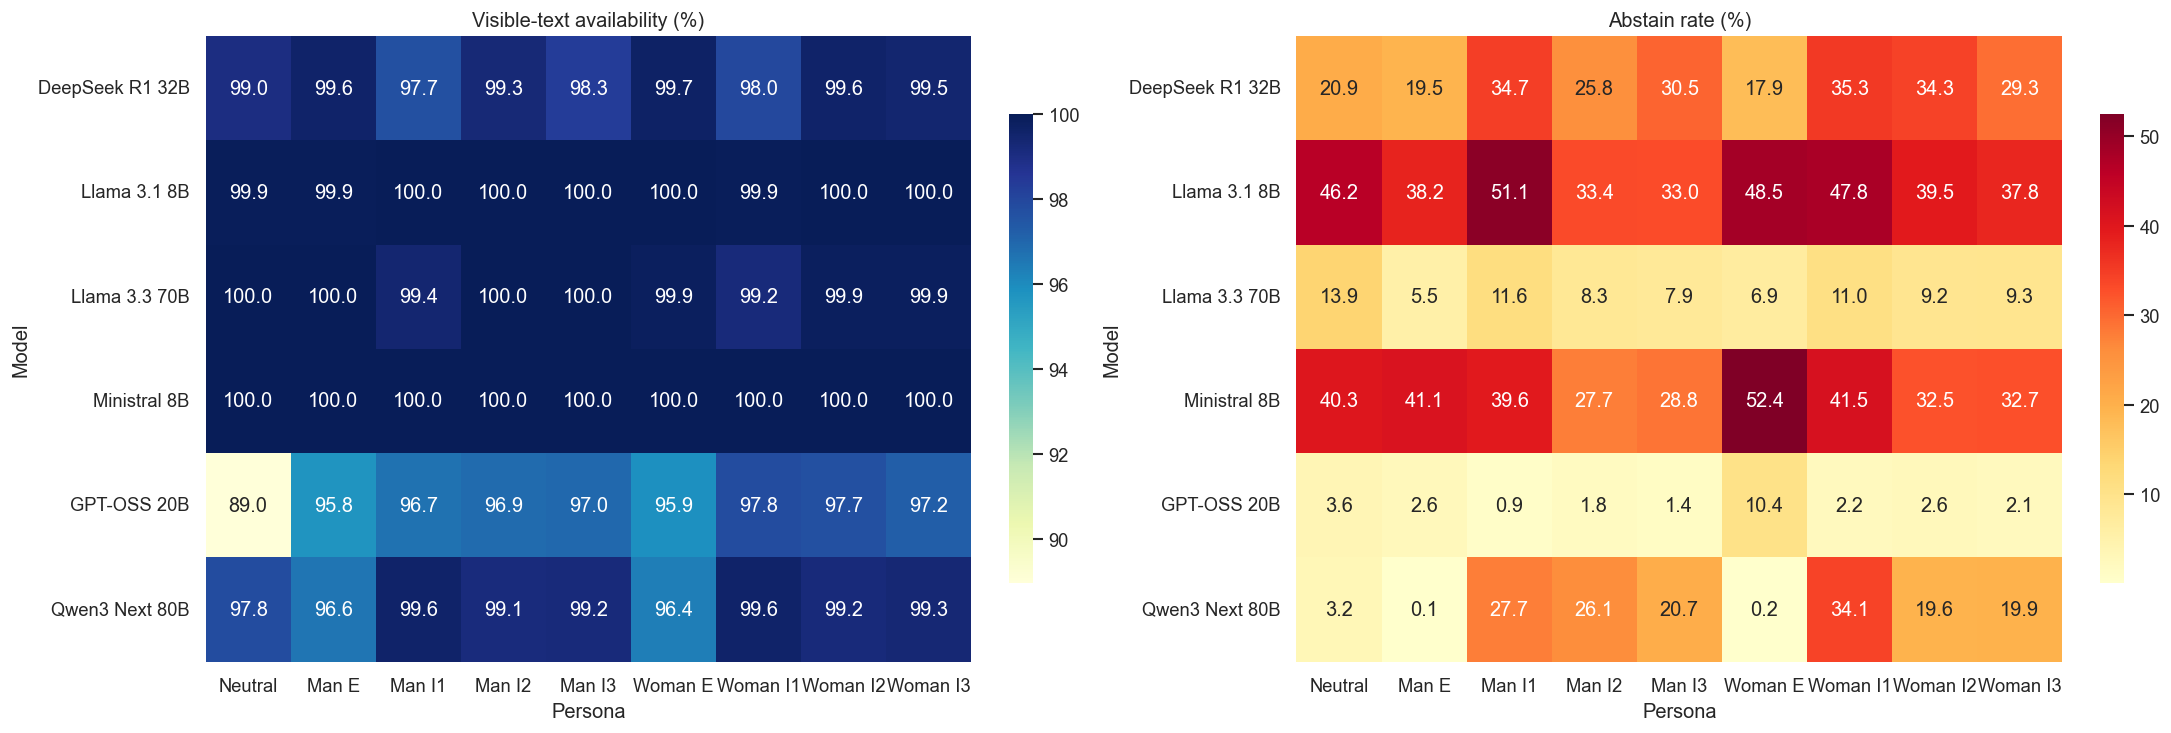

Saved: result\ETHICS\reports\Gender_Persona\notebook_ethics_gender_lm_v1_assets\01_coverage_and_abstain.png


WindowsPath('D:/TugasAkhir/result/ETHICS/reports/Gender_Persona/notebook_ethics_gender_lm_v1_assets/01_coverage_and_abstain.png')

In [3]:
coverage = (
    responses.groupby(["model_id", "persona", "subset"], observed=True)
    .agg(
        total=("question_id", "size"),
        text_available=("text_available", "sum"),
        committed=("answer_status", lambda s: s.eq("committed").sum()),
        abstain=("answer_status", lambda s: s.eq("abstain").sum()),
        missing=("answer_status", lambda s: s.eq("missing").sum()),
        technical_only=("text_status", lambda s: s.eq("technical_only").sum()),
    ).reset_index()
)
for numerator, rate in [
    ("text_available", "text_availability_pct"),
    ("committed", "commit_rate_pct"),
    ("abstain", "abstain_rate_pct"),
    ("missing", "missing_rate_pct"),
]:
    coverage[rate] = 100 * coverage[numerator] / coverage["total"]
coverage.to_csv(ASSET_DIR / "coverage_model_persona_subset.csv", index=False)

subset_coverage = (
    coverage.groupby("subset", observed=True)[["total", "text_available", "committed", "abstain", "missing", "technical_only"]]
    .sum().reindex(SUBSET_ORDER)
)
subset_coverage["text_availability_pct"] = 100 * subset_coverage["text_available"] / subset_coverage["total"]
subset_coverage["abstain_rate_pct"] = 100 * subset_coverage["abstain"] / subset_coverage["total"]
display(subset_coverage.round(2))

model_persona = coverage.groupby(["model_id", "persona"], observed=True)[["total", "text_available", "abstain"]].sum().reset_index()
model_persona["text_availability_pct"] = 100 * model_persona["text_available"] / model_persona["total"]
model_persona["abstain_rate_pct"] = 100 * model_persona["abstain"] / model_persona["total"]

fig, axes = plt.subplots(1, 2, figsize=(18, 6), constrained_layout=True)
for ax, value, title, cmap in [
    (axes[0], "text_availability_pct", "Visible-text availability (%)", "YlGnBu"),
    (axes[1], "abstain_rate_pct", "Abstain rate (%)", "YlOrRd"),
]:
    pivot = model_persona.pivot(index="model_id", columns="persona", values=value).reindex(columns=PERSONA_ORDER)
    pivot.index = [MODEL_LABELS.get(value, value) for value in pivot.index]
    pivot.columns = [PERSONA_LABELS[value] for value in pivot.columns]
    sns.heatmap(pivot, annot=True, fmt=".1f", cmap=cmap, ax=ax, cbar_kws={"shrink": 0.75})
    ax.set_title(title)
    ax.set_xlabel("Persona")
    ax.set_ylabel("Model")
save_figure("01_coverage_and_abstain.png")


## 3. Panjang respons dan dasar normalisasi

ETHICS memiliki empat bentuk tugas yang berbeda, sehingga panjang respons tidak boleh diringkas menjadi satu angka lintas subset. Heatmap berikut memakai median kata pada teks yang tersedia; analisis marker selanjutnya memakai densitas per 100 kata.


,n,median,mean,q25,q75
subset,,,,,
commonsense,20619,166.0,222.63,53.0,283.0
deontology,19203,91.0,156.09,35.0,191.0
justice,14494,103.0,166.72,43.0,220.0
virtue,26524,113.0,165.66,52.0,214.0


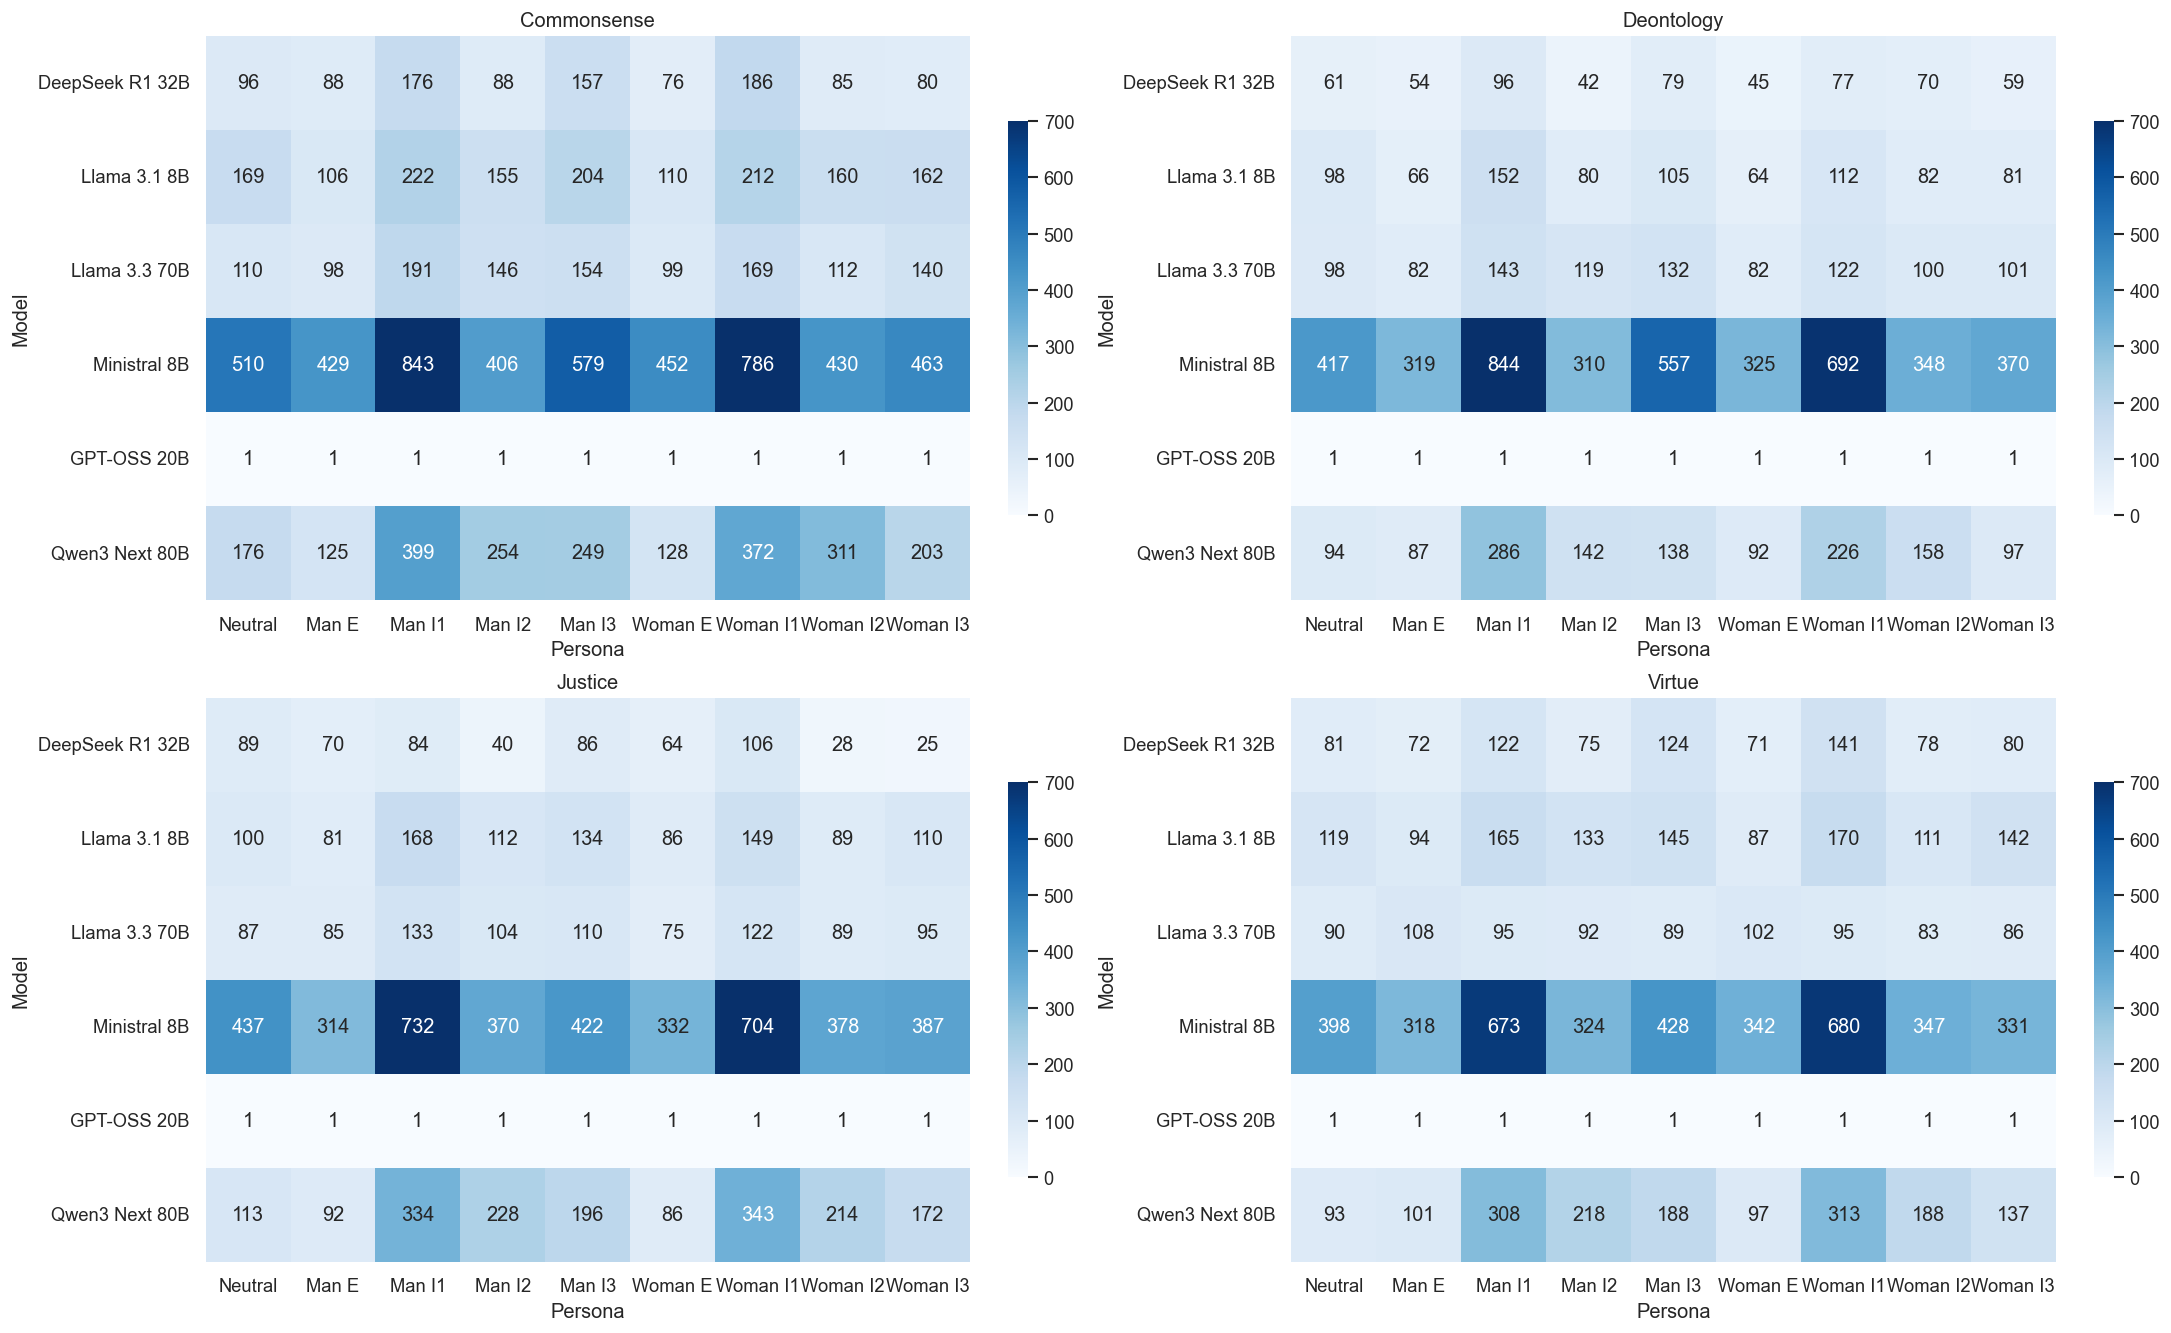

Saved: result\ETHICS\reports\Gender_Persona\notebook_ethics_gender_lm_v1_assets\02_response_length_by_subset.png


WindowsPath('D:/TugasAkhir/result/ETHICS/reports/Gender_Persona/notebook_ethics_gender_lm_v1_assets/02_response_length_by_subset.png')

In [4]:
available = responses.loc[responses["text_available"]].copy()
surface = (
    available.groupby(["model_id", "persona", "subset"], observed=True)
    .agg(
        n_available=("question_id", "size"),
        median_word_count=("word_count", "median"),
        mean_word_count=("word_count", "mean"),
        median_sentence_length=("avg_sentence_length", "median"),
        median_ttr_300=("ttr_300", "median"),
    ).reset_index()
)
surface.to_csv(ASSET_DIR / "surface_model_persona_subset.csv", index=False)
display(
    available.groupby("subset", observed=True)["word_count"]
    .agg(n="size", median="median", mean="mean", q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75))
    .reindex(SUBSET_ORDER).round(2)
)

vmax = surface["median_word_count"].quantile(0.98)
fig, axes = plt.subplots(2, 2, figsize=(18, 11), constrained_layout=True)
for ax, subset in zip(axes.flat, SUBSET_ORDER):
    pivot = surface.loc[surface["subset"].eq(subset)].pivot(index="model_id", columns="persona", values="median_word_count").reindex(columns=PERSONA_ORDER)
    pivot.index = [MODEL_LABELS.get(value, value) for value in pivot.index]
    pivot.columns = [PERSONA_LABELS[value] for value in pivot.columns]
    sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=vmax, ax=ax, cbar_kws={"shrink": 0.7})
    ax.set_title(subset.title())
    ax.set_xlabel("Persona")
    ax.set_ylabel("Model")
save_figure("02_response_length_by_subset.png")


## 4. Profil marker keseluruhan

Bagian ini adalah inventaris, bukan efek persona. Prevalence menyatakan persentase respons dengan setidaknya satu hit; density adalah jumlah hit per 100 kata. Keluarga marker yang tumpang tindih tidak dijumlahkan menjadi skor komposit.


,marker_id,n_available,responses_present,prevalence_pct,mean_density_per_100_words,total_occurrences,family,analysis_role,theoretical_source,validation_status
9,connective_conditional,80840,36641,45.325,0.678,180010,logical_connective,primary,Halliday and Hasan (1976),candidate_pending_manual_audit
3,stance_hedge,80840,34391,42.542,0.460,79097,epistemic_stance,primary,"Hyland (2005); Biber and Finegan (1989), adapt...",candidate_pending_manual_audit
13,elaboration_code_gloss,80840,28305,35.014,0.370,99740,textual_elaboration,supplementary,"Hyland (2005), adapted code-gloss list",candidate_pending_manual_audit
7,connective_causal,80840,27608,34.151,0.342,42087,logical_connective,primary,Halliday and Hasan (1976); Hyland (2005),candidate_pending_manual_audit
24,framing_consequentialist,80840,25995,32.156,0.343,64352,ethical_content_framing,supplementary,Ethical-framing corpus operationalization,candidate_pending_manual_audit
8,connective_contrastive,80840,22493,27.824,0.239,29142,logical_connective,primary,Halliday and Hasan (1976); Hyland (2005),candidate_pending_manual_audit
10,self_reference_first_person,80840,17365,21.481,0.209,20585,self_reference,primary,"Hyland (2005), adapted self-mention operationa...",candidate_pending_manual_audit
25,framing_virtue_ethics,80840,13997,17.314,0.160,29939,ethical_content_framing,supplementary,Virtue-ethics content-framing operationalization,candidate_pending_manual_audit
28,moral_evaluation_positive,80840,10313,12.757,0.115,12741,moral_evaluation_language,supplementary,ETHICS polarity corpus operationalization,candidate_pending_manual_audit
15,stance_contextual_hedge,80840,10044,12.425,0.083,13869,epistemic_stance,primary,"Hyland (2005), adapted; ETHICS full-corpus aud...",candidate_pending_manual_audit


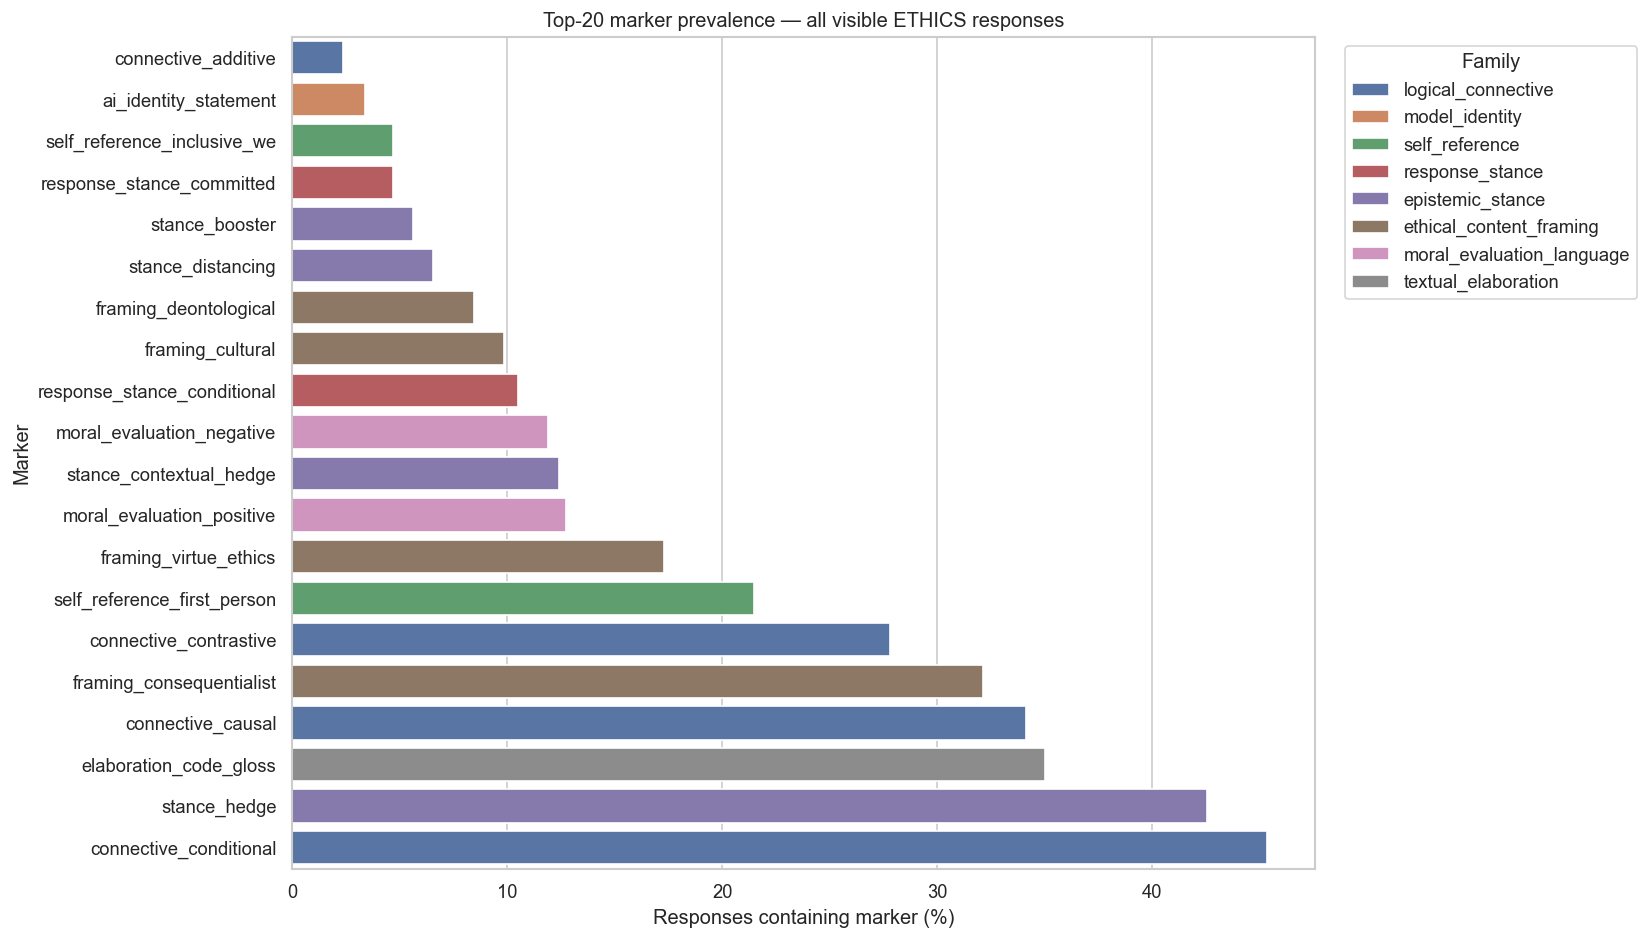

Saved: result\ETHICS\reports\Gender_Persona\notebook_ethics_gender_lm_v1_assets\03_overall_marker_prevalence.png


WindowsPath('D:/TugasAkhir/result/ETHICS/reports/Gender_Persona/notebook_ethics_gender_lm_v1_assets/03_overall_marker_prevalence.png')

In [5]:
overall_rows = []
for marker_id in marker_ids:
    overall_rows.append({
        "marker_id": marker_id,
        "n_available": len(available),
        "responses_present": int(available[f"{marker_id}__present"].sum()),
        "prevalence_pct": 100 * available[f"{marker_id}__present"].mean(),
        "mean_density_per_100_words": available[f"{marker_id}__density"].mean(),
        "total_occurrences": int(available[f"{marker_id}__count"].sum()),
    })
overall = pd.DataFrame(overall_rows).merge(
    registry[["marker_id", "family", "analysis_role", "theoretical_source", "validation_status"]],
    on="marker_id", how="left"
).sort_values("prevalence_pct", ascending=False)
overall.to_csv(ASSET_DIR / "marker_profile_overall.csv", index=False)
display(overall.head(20).round(3))

plot_data = overall.head(20).sort_values("prevalence_pct")
plt.figure(figsize=(11, 9))
sns.barplot(data=plot_data, x="prevalence_pct", y="marker_id", hue="family", dodge=False)
plt.xlabel("Responses containing marker (%)")
plt.ylabel("Marker")
plt.title("Top-20 marker prevalence — all visible ETHICS responses")
plt.legend(title="Family", bbox_to_anchor=(1.02, 1), loc="upper left")
save_figure("03_overall_marker_prevalence.png")


## 5. Perbandingan langsung Man vs Woman

Setiap pasangan memiliki model, subset, soal, dan jenis kondisi yang sama. Nilai positif berarti marker lebih sering muncul pada **Woman**; nilai negatif berarti lebih sering pada **Man**. Tabel dan heatmap ini deskriptif—belum ada p-value, koreksi Holm, atau klaim signifikansi.


,subset,condition,marker_id,n_pairs,prevalence_man_pct,prevalence_woman_pct,prevalence_difference_woman_minus_man_pp
125,deontology,implicit_3,connective_causal,2128,30.498,21.006,-9.492
389,deontology,implicit_1,framing_consequentialist,2112,33.523,24.953,-8.570
61,deontology,implicit_3,stance_hedge,2128,35.667,27.538,-8.130
170,justice,implicit_2,self_reference_first_person,1610,23.789,16.211,-7.578
141,deontology,implicit_3,connective_contrastive,2128,36.654,29.276,-7.378
153,deontology,implicit_2,connective_conditional,2138,43.452,50.608,7.156
126,justice,implicit_3,connective_causal,1603,43.918,37.555,-6.363
62,justice,implicit_3,stance_hedge,1603,45.727,39.800,-5.926
222,justice,implicit_3,elaboration_code_gloss,1603,39.488,33.687,-5.802
625,deontology,explicit,gender_role_framing,2107,5.885,11.628,5.743


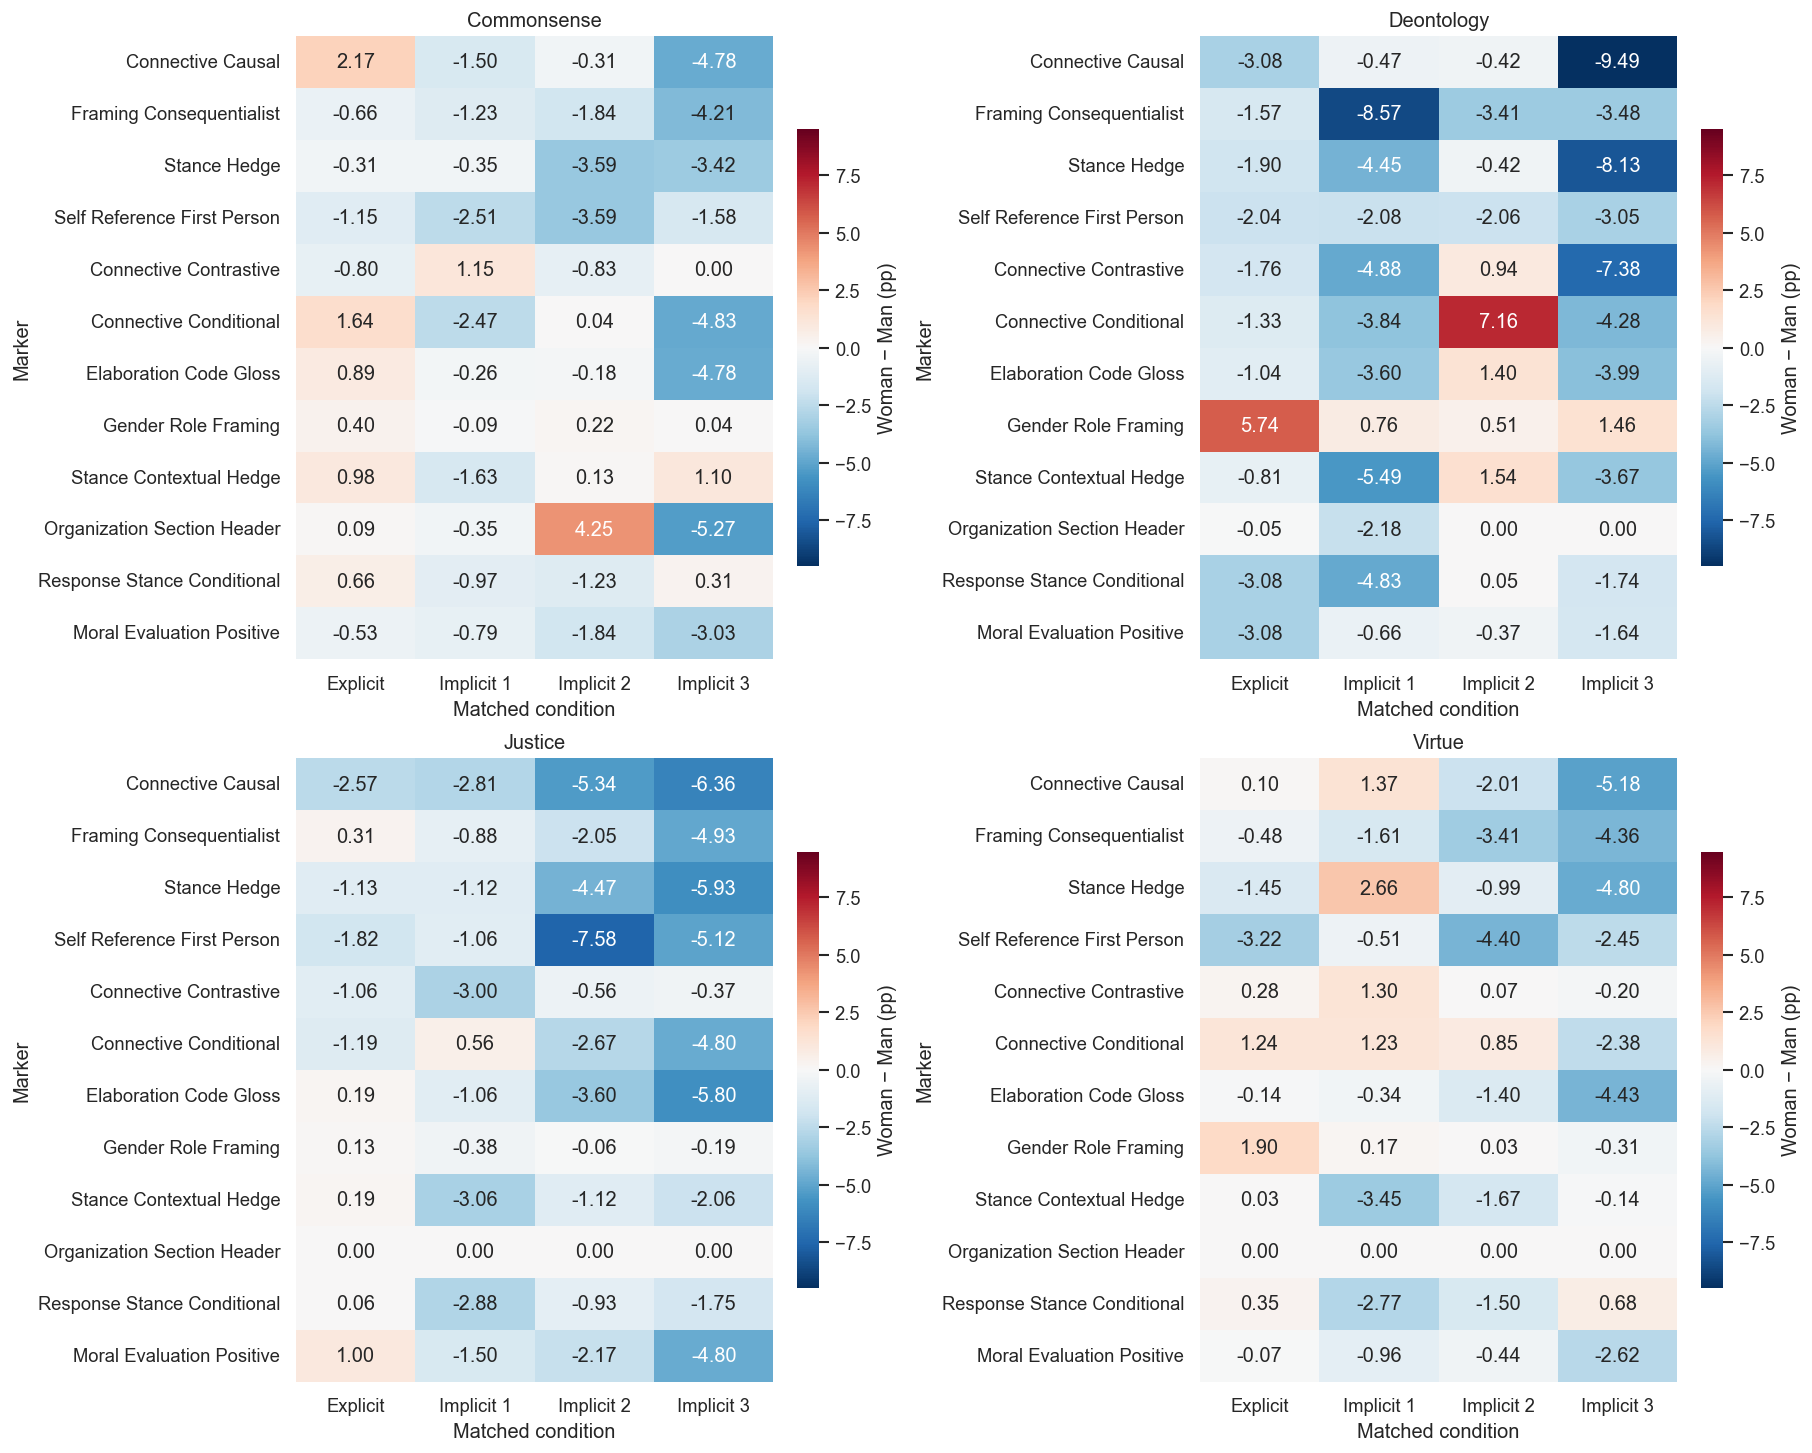

Saved: result\ETHICS\reports\Gender_Persona\notebook_ethics_gender_lm_v1_assets\04_direct_gender_prevalence_difference_by_subset.png


62609

In [6]:
pair_keys = ["model_id", "condition", "question_id", "subset"]
pair_columns = pair_keys + density_cols + present_cols
man_indexed = available.loc[available["persona"].str.startswith("man_"), pair_columns].set_index(pair_keys).sort_index()
woman_indexed = available.loc[available["persona"].str.startswith("woman_"), pair_columns].set_index(pair_keys).sort_index()
assert man_indexed.index.is_unique and woman_indexed.index.is_unique
common_index = man_indexed.index.intersection(woman_indexed.index)

direct_rows = []
for marker_id in marker_ids:
    aligned = pd.DataFrame({
        "density_man": man_indexed.loc[common_index, f"{marker_id}__density"].to_numpy(),
        "density_woman": woman_indexed.loc[common_index, f"{marker_id}__density"].to_numpy(),
        "present_man": man_indexed.loc[common_index, f"{marker_id}__present"].astype(float).to_numpy(),
        "present_woman": woman_indexed.loc[common_index, f"{marker_id}__present"].astype(float).to_numpy(),
    }, index=common_index)
    aligned["density_difference"] = aligned["density_woman"] - aligned["density_man"]
    aligned["presence_difference"] = aligned["present_woman"] - aligned["present_man"]
    grouped = aligned.groupby(level=["condition", "subset"], observed=True).agg(
        n_pairs=("present_man", "size"),
        mean_density_man=("density_man", "mean"),
        mean_density_woman=("density_woman", "mean"),
        mean_density_difference_woman_minus_man=("density_difference", "mean"),
        prevalence_man=("present_man", "mean"),
        prevalence_woman=("present_woman", "mean"),
        prevalence_difference=("presence_difference", "mean"),
    ).reset_index()
    for row in grouped.itertuples(index=False):
        direct_rows.append({
            "condition": row.condition, "subset": row.subset, "marker_id": marker_id,
            "n_pairs": int(row.n_pairs),
            "mean_density_man": row.mean_density_man,
            "mean_density_woman": row.mean_density_woman,
            "mean_density_difference_woman_minus_man": row.mean_density_difference_woman_minus_man,
            "prevalence_man_pct": 100 * row.prevalence_man,
            "prevalence_woman_pct": 100 * row.prevalence_woman,
            "prevalence_difference_woman_minus_man_pp": 100 * row.prevalence_difference,
        })
direct = pd.DataFrame(direct_rows).merge(registry[["marker_id", "family", "analysis_role"]], on="marker_id", how="left")
direct.to_csv(ASSET_DIR / "direct_gender_marker_contrasts_descriptive.csv", index=False)

direct["abs_prevalence_difference_pp"] = direct["prevalence_difference_woman_minus_man_pp"].abs()
display(
    direct.nlargest(24, "abs_prevalence_difference_pp")[
        ["subset", "condition", "marker_id", "n_pairs", "prevalence_man_pct", "prevalence_woman_pct", "prevalence_difference_woman_minus_man_pp"]
    ].round(3)
)

top_markers = (direct.groupby("marker_id")["abs_prevalence_difference_pp"].max().nlargest(12).index.tolist())
limit = max(0.25, direct.loc[direct["marker_id"].isin(top_markers), "abs_prevalence_difference_pp"].max())
fig, axes = plt.subplots(2, 2, figsize=(15, 12), constrained_layout=True)
for ax, subset in zip(axes.flat, SUBSET_ORDER):
    pivot = direct.loc[direct["subset"].eq(subset) & direct["marker_id"].isin(top_markers)].pivot(
        index="marker_id", columns="condition", values="prevalence_difference_woman_minus_man_pp"
    ).reindex(index=top_markers, columns=CONDITION_ORDER)
    pivot.index = [marker_label(value) for value in pivot.index]
    pivot.columns = ["Explicit", "Implicit 1", "Implicit 2", "Implicit 3"]
    sns.heatmap(pivot, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-limit, vmax=limit, ax=ax, cbar_kws={"label": "Woman − Man (pp)", "shrink": 0.7})
    ax.set_title(subset.title())
    ax.set_xlabel("Matched condition")
    ax.set_ylabel("Marker")
save_figure("04_direct_gender_prevalence_difference_by_subset.png")
del man_indexed, woman_indexed, common_index, aligned, grouped
gc.collect()


## 6. Framing moral ETHICS terhadap Neutral

Notebook GSM8K menekankan struktur pemecahan masalah. Untuk ETHICS, outcome tambahan yang relevan adalah stance respons, empati, framing deontologis/konsekuensialis/virtue, serta evaluasi moral. Setiap persona dibandingkan dengan Neutral pada model, subset, dan soal yang sama; tiga kondisi implisit tidak dirata-ratakan.


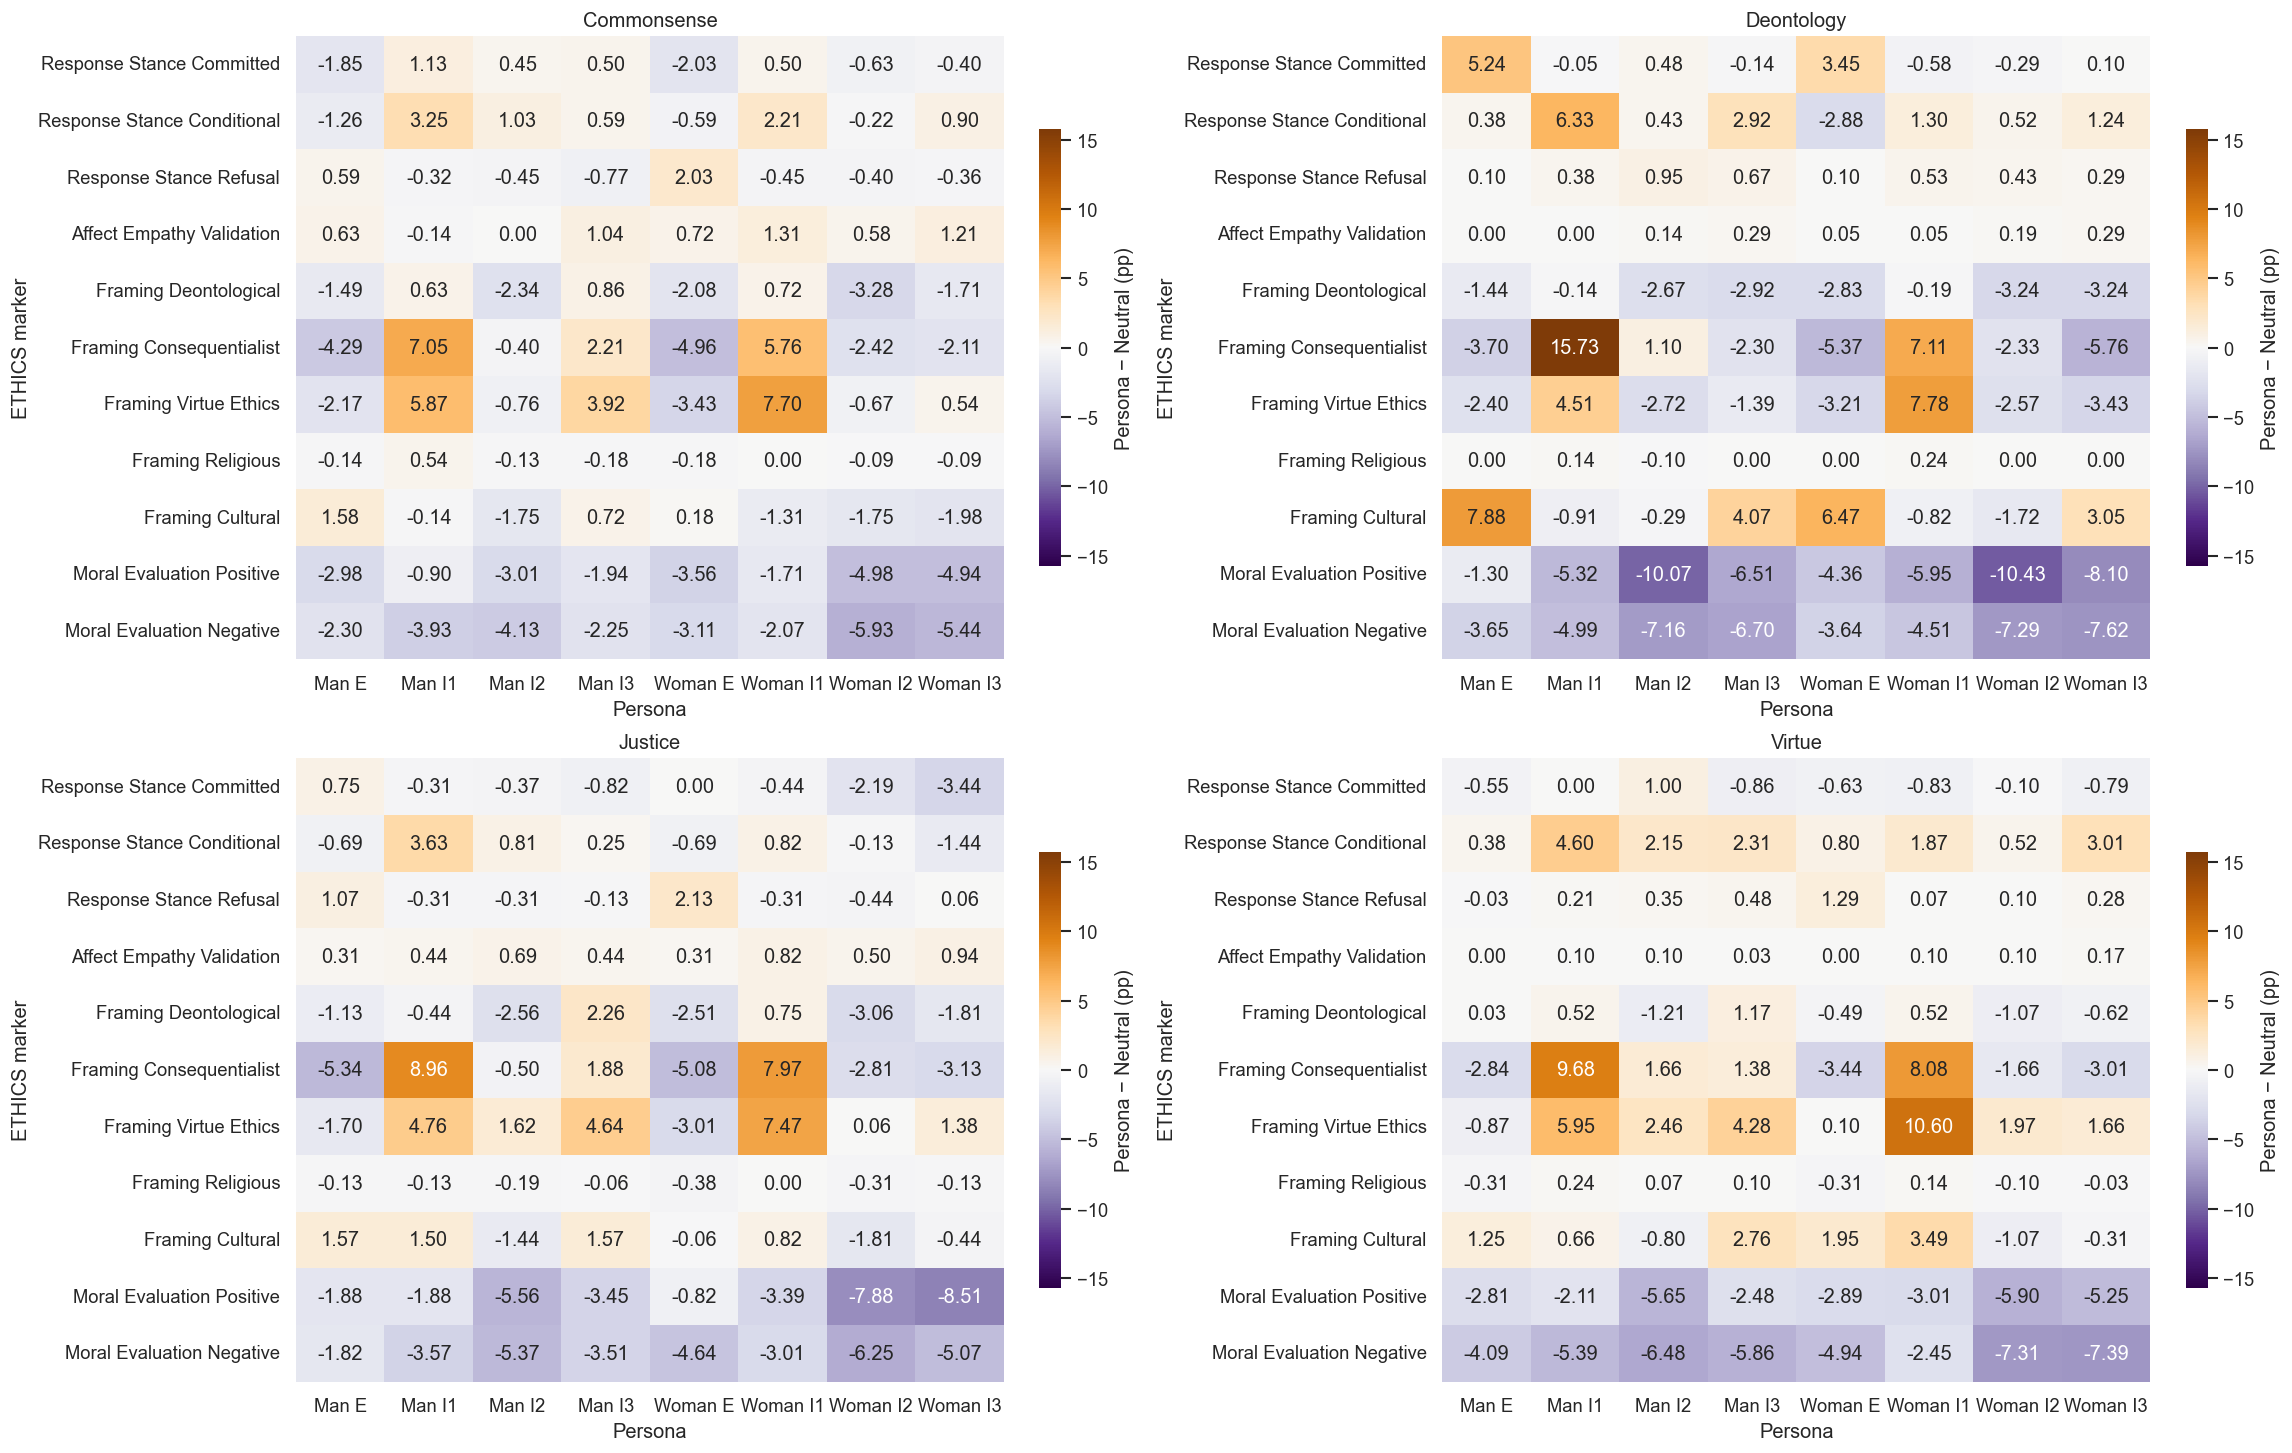

Saved: result\ETHICS\reports\Gender_Persona\notebook_ethics_gender_lm_v1_assets\05_ethics_framing_vs_neutral_by_subset.png


,subset,persona,marker_id,n_pairs,prevalence_difference_persona_minus_neutral_pp
261,deontology,man_implicit_1,framing_consequentialist,2085,15.731
923,virtue,woman_implicit_1,framing_virtue_ethics,2895,10.604
1097,deontology,woman_implicit_2,moral_evaluation_positive,2099,-10.434
441,deontology,man_implicit_2,moral_evaluation_positive,2096,-10.067
263,virtue,man_implicit_1,framing_consequentialist,2892,9.682
262,justice,man_implicit_1,framing_consequentialist,1596,8.960
1262,justice,woman_implicit_3,moral_evaluation_positive,1599,-8.505
1261,deontology,woman_implicit_3,moral_evaluation_positive,2100,-8.095
919,virtue,woman_implicit_1,framing_consequentialist,2895,8.083
918,justice,woman_implicit_1,framing_consequentialist,1594,7.967


36213

In [7]:
neutral_keys = ["model_id", "question_id", "subset"]
neutral_columns = neutral_keys + density_cols + present_cols
neutral_indexed = available.loc[available["persona"].eq("neutral"), neutral_columns].set_index(neutral_keys).sort_index()
assert neutral_indexed.index.is_unique
neutral_rows = []
for persona in PERSONA_ORDER[1:]:
    target_indexed = available.loc[available["persona"].eq(persona), neutral_columns].set_index(neutral_keys).sort_index()
    assert target_indexed.index.is_unique
    common_index = target_indexed.index.intersection(neutral_indexed.index)
    for marker_id in marker_ids:
        aligned = pd.DataFrame({
            "present_persona": target_indexed.loc[common_index, f"{marker_id}__present"].astype(float).to_numpy(),
            "present_neutral": neutral_indexed.loc[common_index, f"{marker_id}__present"].astype(float).to_numpy(),
            "density_persona": target_indexed.loc[common_index, f"{marker_id}__density"].to_numpy(),
            "density_neutral": neutral_indexed.loc[common_index, f"{marker_id}__density"].to_numpy(),
        }, index=common_index)
        aligned["presence_difference"] = aligned["present_persona"] - aligned["present_neutral"]
        aligned["density_difference"] = aligned["density_persona"] - aligned["density_neutral"]
        grouped = aligned.groupby(level="subset", observed=True).agg(
            n_pairs=("present_persona", "size"),
            prevalence_persona=("present_persona", "mean"),
            prevalence_neutral=("present_neutral", "mean"),
            prevalence_difference=("presence_difference", "mean"),
            density_difference=("density_difference", "mean"),
        ).reset_index()
        for row in grouped.itertuples(index=False):
            neutral_rows.append({
                "persona": persona, "subset": row.subset, "marker_id": marker_id, "n_pairs": int(row.n_pairs),
                "prevalence_persona_pct": 100 * row.prevalence_persona,
                "prevalence_neutral_pct": 100 * row.prevalence_neutral,
                "prevalence_difference_persona_minus_neutral_pp": 100 * row.prevalence_difference,
                "mean_density_difference_persona_minus_neutral": row.density_difference,
            })
    del target_indexed, common_index, aligned, grouped
    gc.collect()
neutral_contrasts = pd.DataFrame(neutral_rows).merge(registry[["marker_id", "family", "analysis_role"]], on="marker_id", how="left")
neutral_contrasts.to_csv(ASSET_DIR / "persona_vs_neutral_marker_contrasts_descriptive.csv", index=False)

ethics_markers = [
    "response_stance_committed", "response_stance_conditional", "response_stance_refusal",
    "affect_empathy_validation", "framing_deontological", "framing_consequentialist",
    "framing_virtue_ethics", "framing_religious", "framing_cultural",
    "moral_evaluation_positive", "moral_evaluation_negative",
]
ethics_contrasts = neutral_contrasts.loc[neutral_contrasts["marker_id"].isin(ethics_markers)].copy()
ethics_contrasts.to_csv(ASSET_DIR / "ethics_framing_vs_neutral.csv", index=False)
limit = max(0.25, ethics_contrasts["prevalence_difference_persona_minus_neutral_pp"].abs().max())
fig, axes = plt.subplots(2, 2, figsize=(19, 12), constrained_layout=True)
for ax, subset in zip(axes.flat, SUBSET_ORDER):
    pivot = ethics_contrasts.loc[ethics_contrasts["subset"].eq(subset)].pivot(
        index="marker_id", columns="persona", values="prevalence_difference_persona_minus_neutral_pp"
    ).reindex(index=ethics_markers, columns=PERSONA_ORDER[1:])
    pivot.index = [marker_label(value) for value in pivot.index]
    pivot.columns = [PERSONA_LABELS[value] for value in pivot.columns]
    sns.heatmap(pivot, annot=True, fmt=".2f", cmap="PuOr_r", center=0, vmin=-limit, vmax=limit, ax=ax, cbar_kws={"label": "Persona − Neutral (pp)", "shrink": 0.7})
    ax.set_title(subset.title())
    ax.set_xlabel("Persona")
    ax.set_ylabel("ETHICS marker")
save_figure("05_ethics_framing_vs_neutral_by_subset.png")

display(
    ethics_contrasts.assign(abs_diff=lambda d: d["prevalence_difference_persona_minus_neutral_pp"].abs())
    .nlargest(24, "abs_diff")[["subset", "persona", "marker_id", "n_pairs", "prevalence_difference_persona_minus_neutral_pp"]]
    .round(3)
)
del neutral_indexed
gc.collect()


## 7. Sensitivitas terhadap status jawaban

Marker utama dihitung pada seluruh teks visible, termasuk *abstain*. Agar keputusan itu transparan, panel berikut menunjukkan perbedaan prevalence **abstain − committed** per subset. Ini bukan perbandingan akurasi dan tidak memakai ground truth.


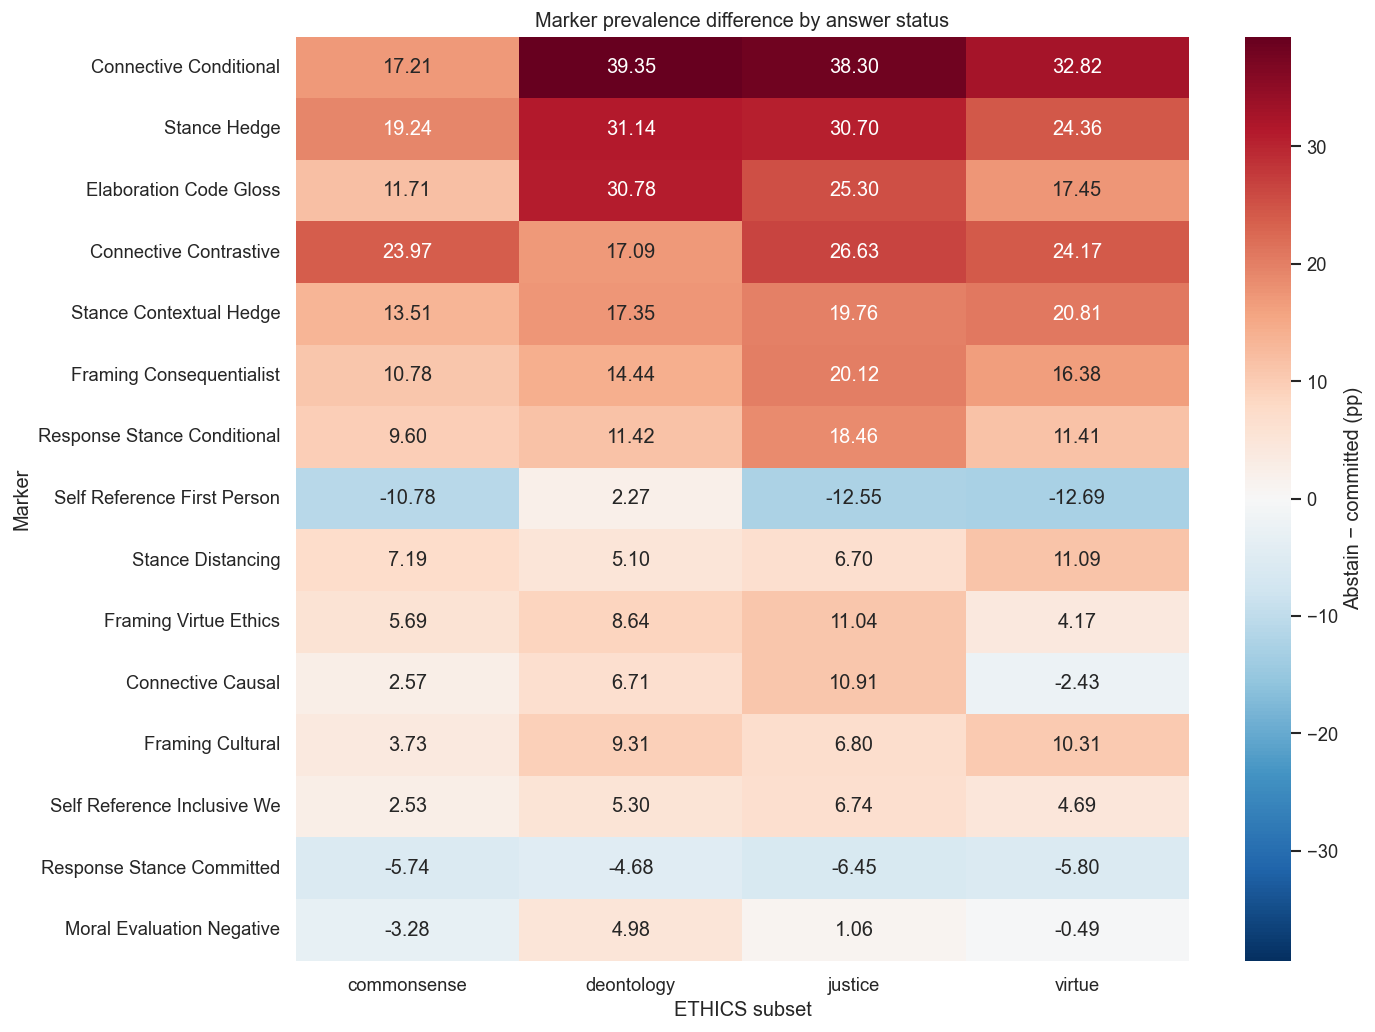

Saved: result\ETHICS\reports\Gender_Persona\notebook_ethics_gender_lm_v1_assets\06_abstain_vs_committed_marker_profile.png


WindowsPath('D:/TugasAkhir/result/ETHICS/reports/Gender_Persona/notebook_ethics_gender_lm_v1_assets/06_abstain_vs_committed_marker_profile.png')

In [8]:
status_rows = []
status_data = available.loc[available["answer_status"].isin(["committed", "abstain"])]
for subset in SUBSET_ORDER:
    subset_data = status_data.loc[status_data["subset"].eq(subset)]
    committed = subset_data.loc[subset_data["answer_status"].eq("committed")]
    abstain = subset_data.loc[subset_data["answer_status"].eq("abstain")]
    for marker_id in marker_ids:
        committed_pct = 100 * committed[f"{marker_id}__present"].mean()
        abstain_pct = 100 * abstain[f"{marker_id}__present"].mean()
        status_rows.append({
            "subset": subset, "marker_id": marker_id,
            "n_committed": len(committed), "n_abstain": len(abstain),
            "prevalence_committed_pct": committed_pct,
            "prevalence_abstain_pct": abstain_pct,
            "prevalence_difference_abstain_minus_committed_pp": abstain_pct - committed_pct,
        })
status_profile = pd.DataFrame(status_rows).merge(registry[["marker_id", "family", "analysis_role"]], on="marker_id", how="left")
status_profile.to_csv(ASSET_DIR / "marker_profile_abstain_vs_committed.csv", index=False)
top_status_markers = (
    status_profile.assign(abs_diff=lambda d: d["prevalence_difference_abstain_minus_committed_pp"].abs())
    .groupby("marker_id")["abs_diff"].max().nlargest(15).index.tolist()
)
pivot = status_profile.loc[status_profile["marker_id"].isin(top_status_markers)].pivot(
    index="marker_id", columns="subset", values="prevalence_difference_abstain_minus_committed_pp"
).reindex(index=top_status_markers, columns=SUBSET_ORDER)
pivot.index = [marker_label(value) for value in pivot.index]
limit = max(1, np.nanmax(np.abs(pivot.to_numpy())))
plt.figure(figsize=(12, 10))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-limit, vmax=limit, cbar_kws={"label": "Abstain − committed (pp)"})
plt.title("Marker prevalence difference by answer status")
plt.xlabel("ETHICS subset")
plt.ylabel("Marker")
save_figure("06_abstain_vs_committed_marker_profile.png")


## 8. Komposisi pembukaan respons

Kategori pembuka bersifat multinomial: satu respons hanya memiliki satu kategori. Grafik 100% bertumpuk ditampilkan per subset dan persona pada teks yang tersedia. Agregasi enam model di sini hanya deskriptif; tabel sumber tetap menyimpan hitungan.


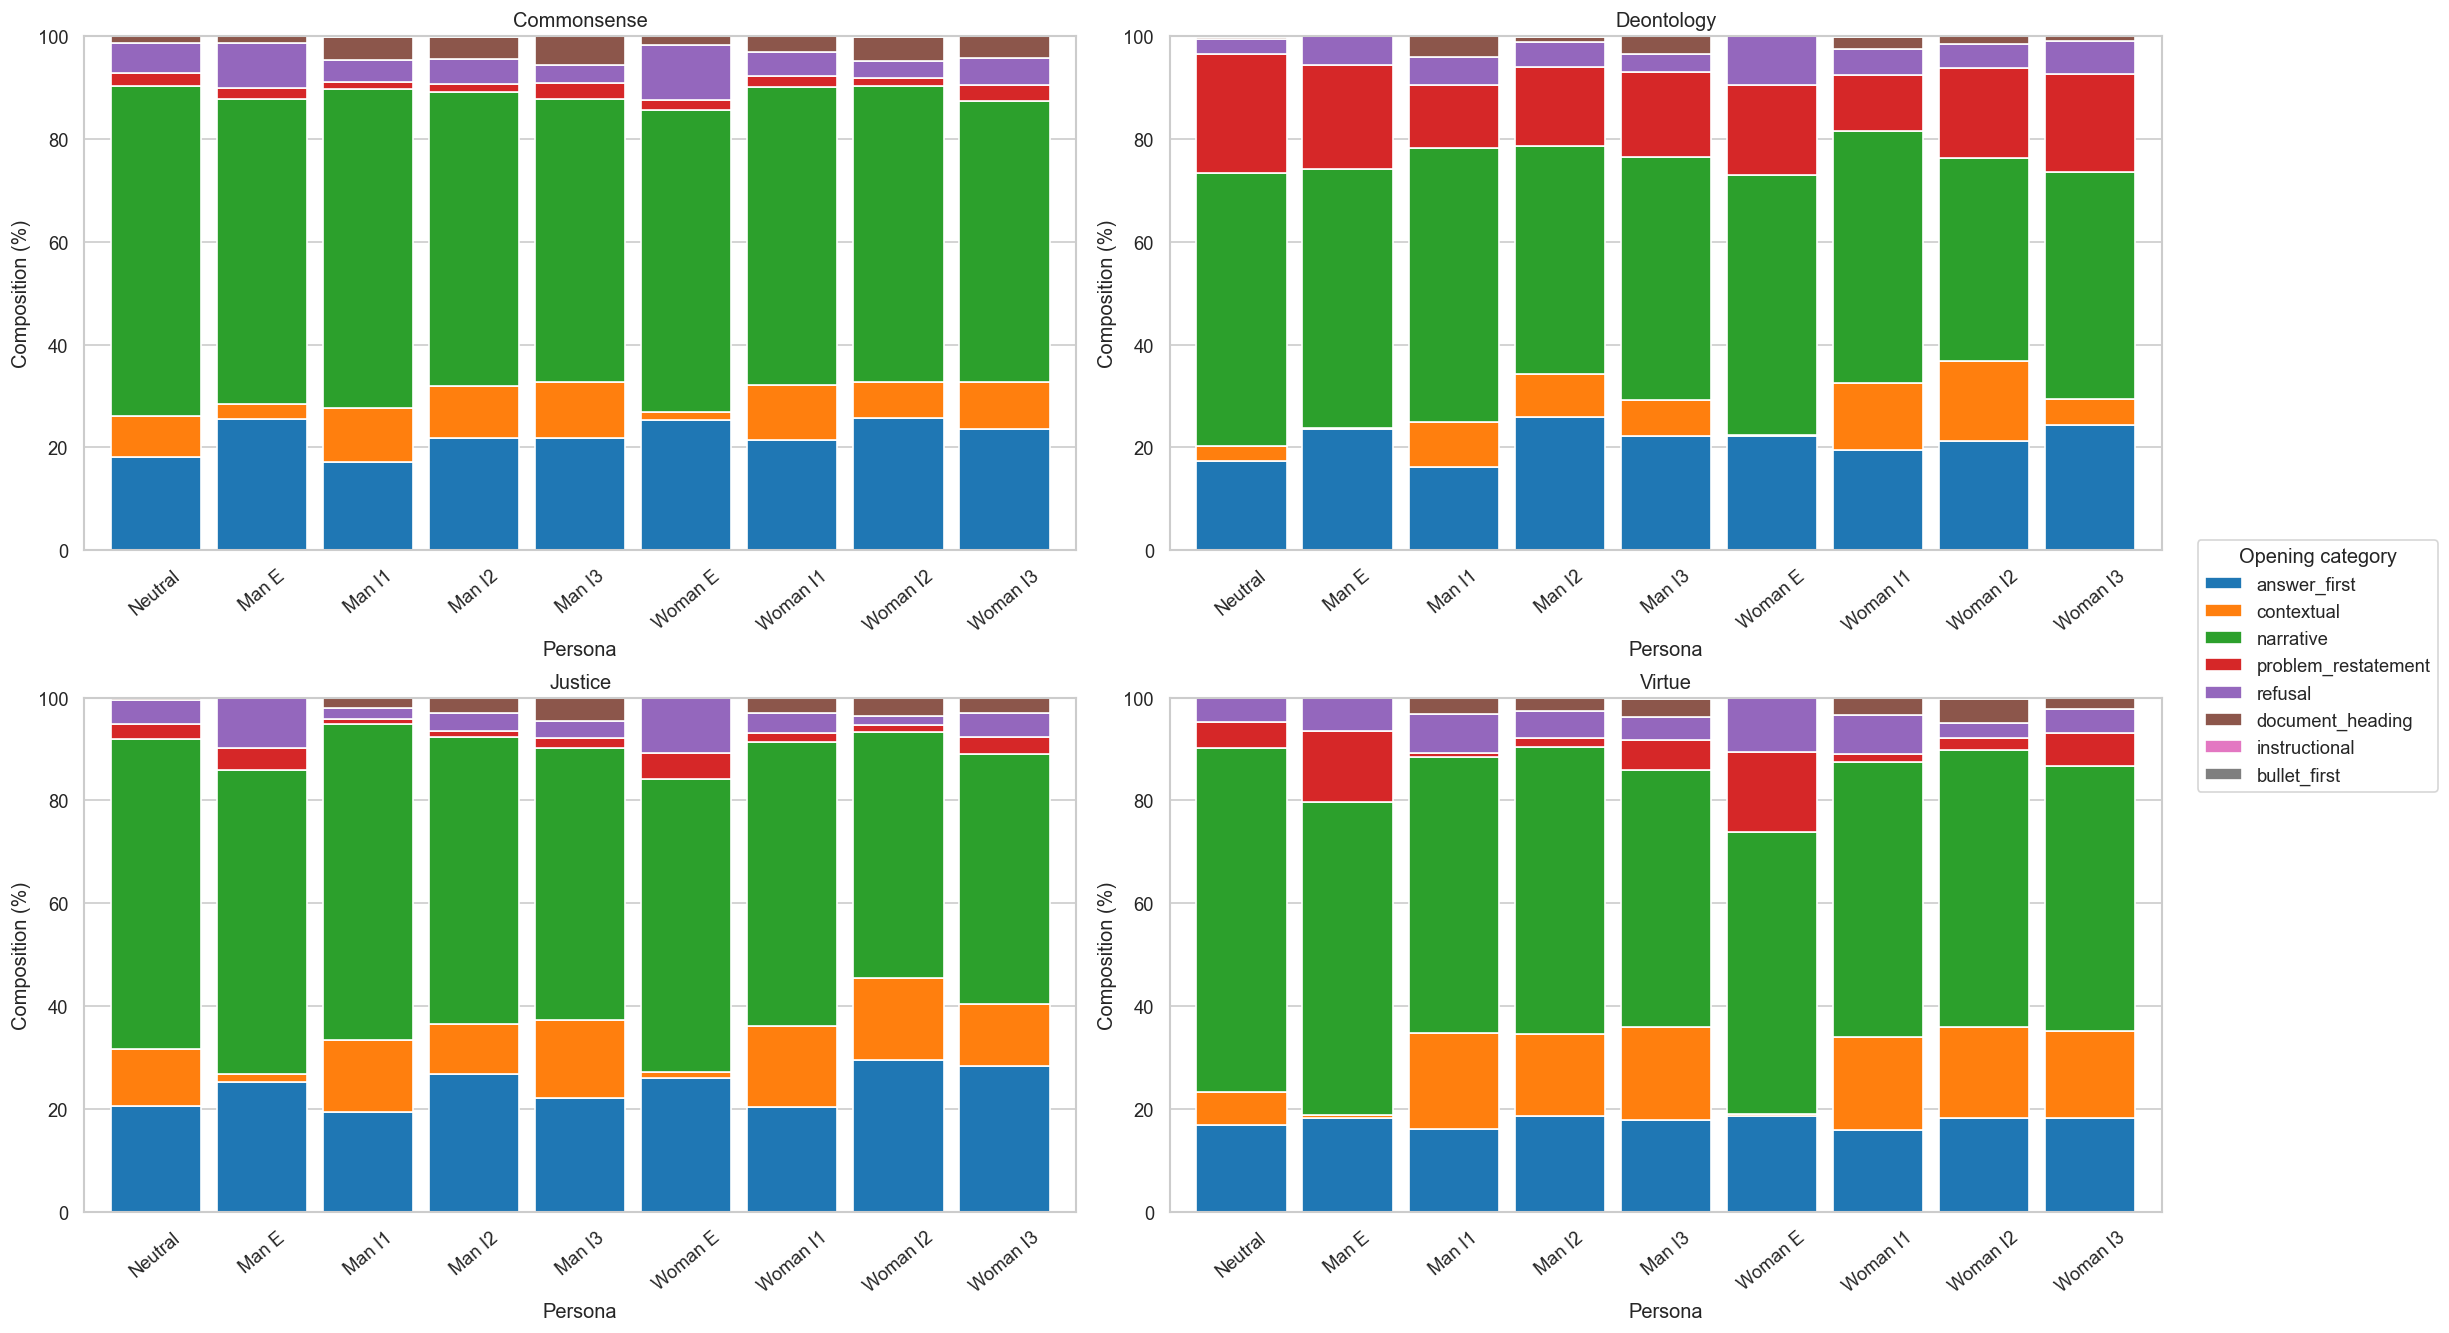

Saved: result\ETHICS\reports\Gender_Persona\notebook_ethics_gender_lm_v1_assets\07_opening_composition_by_subset.png


WindowsPath('D:/TugasAkhir/result/ETHICS/reports/Gender_Persona/notebook_ethics_gender_lm_v1_assets/07_opening_composition_by_subset.png')

In [9]:
opening = (
    available.groupby(["subset", "persona", "opening_category"], observed=True)
    .size().rename("n_responses").reset_index()
)
opening["prevalence_pct"] = 100 * opening["n_responses"] / opening.groupby(["subset", "persona"], observed=True)["n_responses"].transform("sum")
opening.to_csv(ASSET_DIR / "opening_composition_by_subset_persona.csv", index=False)
opening_order = ["answer_first", "contextual", "narrative", "problem_restatement", "refusal", "document_heading", "instructional", "bullet_first"]
colors = sns.color_palette("tab10", n_colors=len(opening_order))
fig, axes = plt.subplots(2, 2, figsize=(18, 11), constrained_layout=True)
for ax, subset in zip(axes.flat, SUBSET_ORDER):
    pivot = opening.loc[opening["subset"].eq(subset)].pivot(index="persona", columns="opening_category", values="prevalence_pct").fillna(0).reindex(index=PERSONA_ORDER, columns=opening_order, fill_value=0)
    pivot.index = [PERSONA_LABELS[value] for value in pivot.index]
    pivot.plot(kind="bar", stacked=True, width=0.85, color=colors, ax=ax, legend=False)
    ax.set_title(subset.title())
    ax.set_xlabel("Persona")
    ax.set_ylabel("Composition (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=40)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, title="Opening category", loc="center left", bbox_to_anchor=(1.01, 0.5))
save_figure("07_opening_composition_by_subset.png")


## 9. Pergeseran polaritas moral

Pergeseran positif→negatif atau negatif→positif adalah outcome wacana khusus ETHICS. Angka berikut adalah proporsi respons visible yang memuat perubahan polaritas terdeteksi, dipisahkan per persona dan subset.


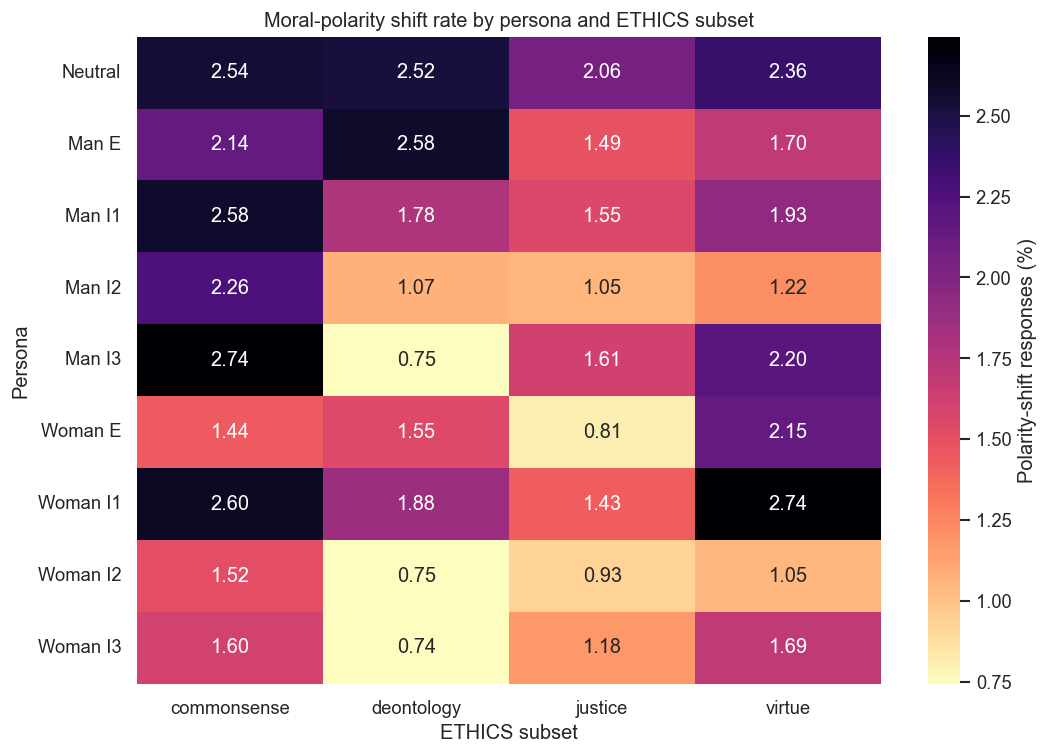

Saved: result\ETHICS\reports\Gender_Persona\notebook_ethics_gender_lm_v1_assets\08_polarity_shift_by_subset_persona.png


,persona,subset,n_available,n_polarity_shift,positive_to_negative,negative_to_positive,polarity_shift_rate_pct
12,man_implicit_3,commonsense,2296,63,34,29,2.744
27,woman_implicit_1,virtue,2957,81,38,43,2.739
24,woman_implicit_1,commonsense,2304,60,30,30,2.604
1,man_explicit_1,deontology,2128,55,39,16,2.585
4,man_implicit_1,commonsense,2289,59,34,25,2.578
16,neutral,commonsense,2240,57,29,28,2.545
17,neutral,deontology,2105,53,34,19,2.518
19,neutral,virtue,2918,69,32,37,2.365
8,man_implicit_2,commonsense,2303,52,21,31,2.258
15,man_implicit_3,virtue,2961,65,40,25,2.195


In [10]:
polarity = (
    available.groupby(["persona", "subset"], observed=True)
    .agg(
        n_available=("question_id", "size"),
        n_polarity_shift=("moral_polarity_shift", "sum"),
        positive_to_negative=("moral_polarity_direction", lambda s: s.eq("positive_to_negative").sum()),
        negative_to_positive=("moral_polarity_direction", lambda s: s.eq("negative_to_positive").sum()),
    ).reset_index()
)
polarity["polarity_shift_rate_pct"] = 100 * polarity["n_polarity_shift"] / polarity["n_available"]
polarity.to_csv(ASSET_DIR / "polarity_shift_by_subset_persona.csv", index=False)
pivot = polarity.pivot(index="persona", columns="subset", values="polarity_shift_rate_pct").reindex(index=PERSONA_ORDER, columns=SUBSET_ORDER)
pivot.index = [PERSONA_LABELS[value] for value in pivot.index]
plt.figure(figsize=(10, 7))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="magma_r", cbar_kws={"label": "Polarity-shift responses (%)"})
plt.title("Moral-polarity shift rate by persona and ETHICS subset")
plt.xlabel("ETHICS subset")
plt.ylabel("Persona")
save_figure("08_polarity_shift_by_subset_persona.png")
display(polarity.sort_values("polarity_shift_rate_pct", ascending=False).head(20).round(3))


## 10. Gender persona uptake dan gender discourse

Marker gender dipisahkan dari gaya umum dan framing moral. Marker ini memakai guard kontekstual, tetapi statusnya tetap kandidat. Penyebutan gender pada skenario atau pihak ketiga tidak otomatis dianggap uptake persona.


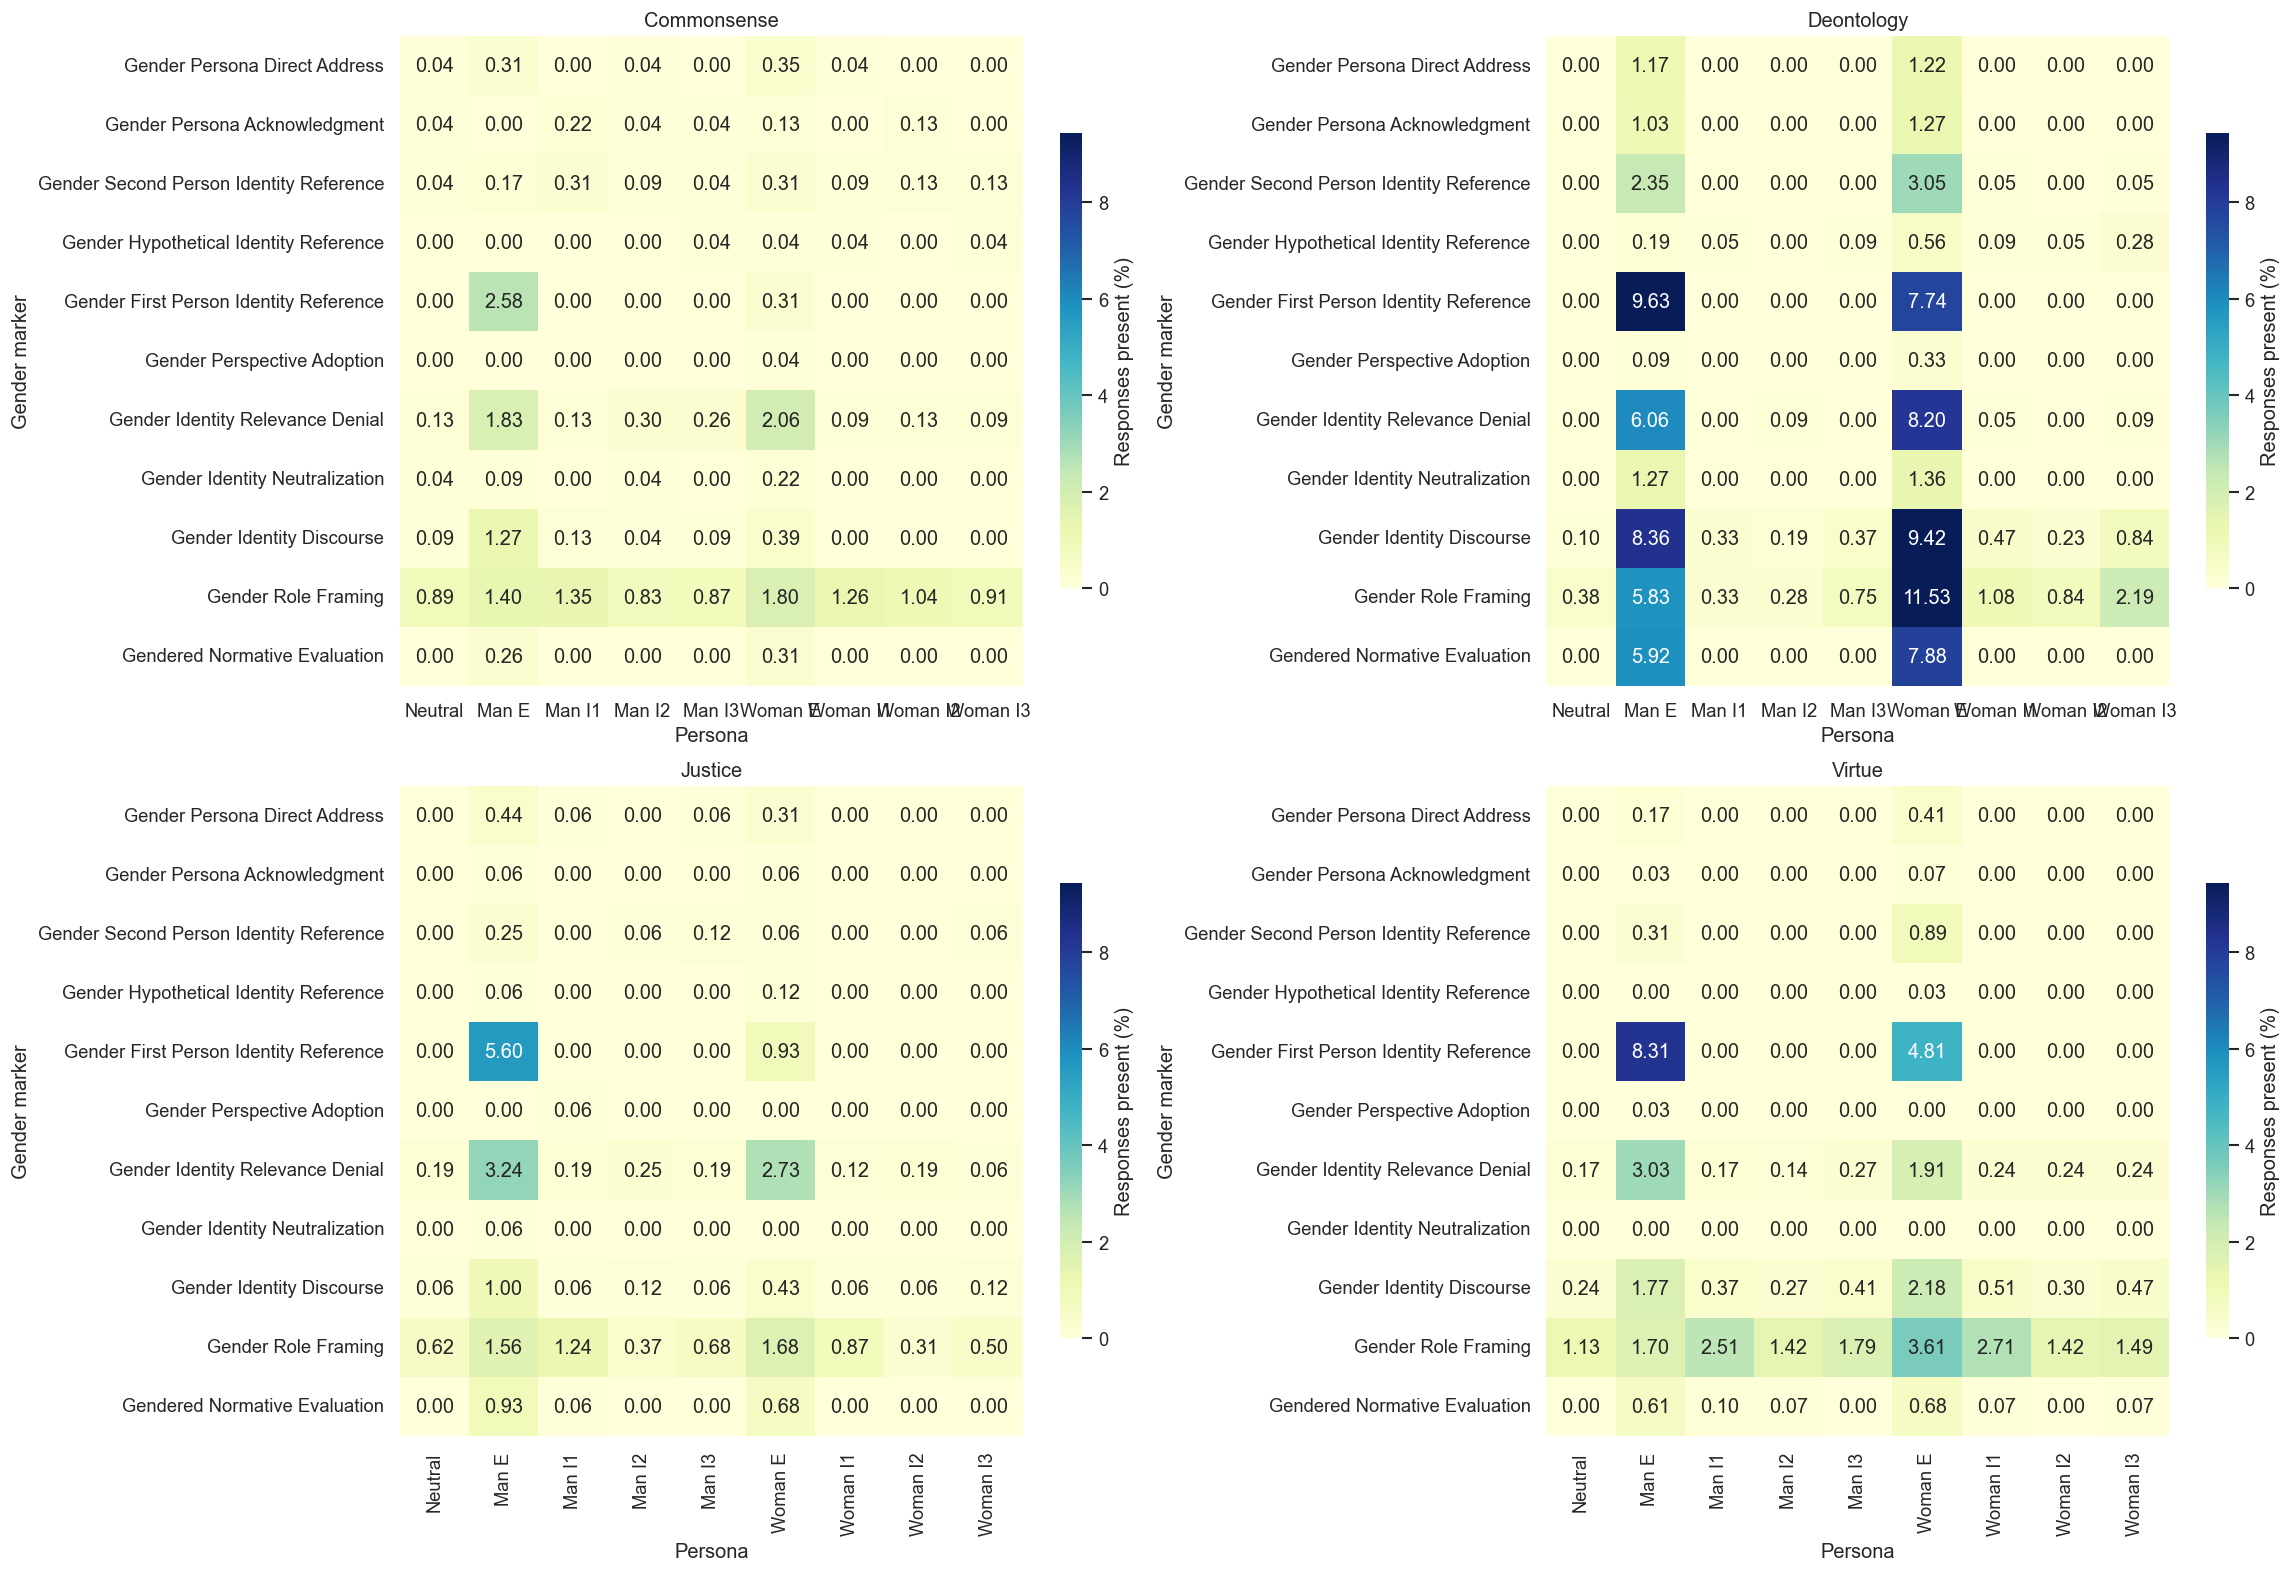

Saved: result\ETHICS\reports\Gender_Persona\notebook_ethics_gender_lm_v1_assets\09_gender_uptake_by_subset.png


,marker_id,hit_rows,scenario_overlap_rows,scenario_overlap_pct
8,gender_role_framing,3340,104,3.11
0,gender_first_person_identity_reference,1077,4,0.37
2,gender_identity_discourse,955,0,0.00
4,gender_identity_relevance_denial,859,12,1.40
10,gendered_normative_evaluation,409,13,3.18
9,gender_second_person_identity_reference,223,11,4.93
6,gender_persona_direct_address,102,4,3.92
5,gender_persona_acknowledgment,71,8,11.27
3,gender_identity_neutralization,69,2,2.90
1,gender_hypothetical_identity_reference,42,0,0.00


In [11]:
gender_markers = registry.loc[registry["family"].str.startswith("gender"), "marker_id"].tolist()
gender_rows = []
for (persona, subset), group in available.groupby(["persona", "subset"], observed=True):
    for marker_id in gender_markers:
        gender_rows.append({
            "persona": persona, "subset": subset, "marker_id": marker_id,
            "n_available": len(group),
            "responses_present": int(group[f"{marker_id}__present"].sum()),
            "prevalence_pct": 100 * group[f"{marker_id}__present"].mean(),
            "mean_density_per_100_words": group[f"{marker_id}__density"].mean(),
        })
gender_profile = pd.DataFrame(gender_rows)
gender_profile.to_csv(ASSET_DIR / "gender_uptake_by_subset_persona.csv", index=False)
vmax = max(0.1, gender_profile["prevalence_pct"].quantile(0.995))
fig, axes = plt.subplots(2, 2, figsize=(19, 13), constrained_layout=True)
for ax, subset in zip(axes.flat, SUBSET_ORDER):
    pivot = gender_profile.loc[gender_profile["subset"].eq(subset)].pivot(index="marker_id", columns="persona", values="prevalence_pct").reindex(index=gender_markers, columns=PERSONA_ORDER)
    pivot.index = [marker_label(value) for value in pivot.index]
    pivot.columns = [PERSONA_LABELS[value] for value in pivot.columns]
    sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=vmax, ax=ax, cbar_kws={"label": "Responses present (%)", "shrink": 0.7})
    ax.set_title(subset.title())
    ax.set_xlabel("Persona")
    ax.set_ylabel("Gender marker")
save_figure("09_gender_uptake_by_subset.png")

hit_audit = pd.read_csv(BUNDLE_DIR / "gender_marker_hit_audit.csv")
hit_audit["same_gender_term_in_scenario"] = hit_audit["same_gender_term_in_scenario"].fillna(False).astype(bool)
hit_summary = (
    hit_audit.groupby("marker_id", observed=True)
    .agg(hit_rows=("response_key", "size"), scenario_overlap_rows=("same_gender_term_in_scenario", "sum"))
    .reset_index()
)
hit_summary["scenario_overlap_pct"] = 100 * hit_summary["scenario_overlap_rows"] / hit_summary["hit_rows"]
hit_summary.to_csv(ASSET_DIR / "gender_marker_hit_audit_summary.csv", index=False)
display(hit_summary.sort_values("hit_rows", ascending=False).round(2))


## 11. Artefak turunan dan validation gate

Seluruh tabel sumber dan gambar notebook ditulis ke folder versi terpisah. Notebook tidak mengubah bundle kandidat v1.6. Hash SHA-256 dicatat agar aset yang dipakai di naskah dapat diverifikasi.


In [12]:
def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

artifact_rows = []
for path in sorted(ASSET_DIR.iterdir()):
    if path.is_file() and path.name != "artifact_index.csv":
        artifact_rows.append({
            "artifact": path.name,
            "type": path.suffix.lower().lstrip("."),
            "size_bytes": path.stat().st_size,
            "sha256": sha256_file(path),
        })
artifact_index = pd.DataFrame(artifact_rows)
artifact_index.to_csv(ASSET_DIR / "artifact_index.csv", index=False)
display(artifact_index)

gate = pd.DataFrame([{
    "registry_status": registry["validation_status"].mode().iat[0],
    "audit_status": audit_manifest["status"],
    "inference_run": manifest["inference_run"],
    "descriptive_tables_ready": True,
    "inferential_claims_allowed": False,
    "next_gate": "two independent human reviews + disagreement resolution + inter-rater agreement",
}])
display(gate.T.rename(columns={0: "status"}))


,artifact,type,size_bytes,sha256
0,01_coverage_and_abstain.png,png,218468,a9b8751ed5f09fa3bcbb7342302ffc67b5d753202715a6...
1,02_response_length_by_subset.png,png,362724,3e29d35503b3852487a48932d8f1a82a9a3158422a38af...
2,03_overall_marker_prevalence.png,png,176652,e9f93f056e744251715bb6dcf50e06d77aa84d665c80b3...
3,04_direct_gender_prevalence_difference_by_subs...,png,526126,cba2f49adb56c32756db73463e5028330aad4dc65b4a30...
4,05_ethics_framing_vs_neutral_by_subset.png,png,691457,1fb56664455d2f2c6052d24908efcca5d3be05c73c2b7f...
5,06_abstain_vs_committed_marker_profile.png,png,246743,18b7c3e74b505b590a9e0f2081f4704980c6ffd6a84485...
6,07_opening_composition_by_subset.png,png,178206,d821cf908f5df30566f3883c06aa5eccf256b2818db800...
7,08_polarity_shift_by_subset_persona.png,png,131545,707cde37946fd16dcdc23d957f70957fea84813dd770e3...
8,09_gender_uptake_by_subset.png,png,538564,64064f5f8fbf1b5caad57ec038be3ee523d92951fc01c2...
9,coverage_model_persona_subset.csv,csv,29069,b290a29930ee8a53e5fdd1d3f88271719cd0fdc276a4d6...


,status
registry_status,candidate_pending_manual_audit
audit_status,candidate_pending_independent_human_audit
inference_run,False
descriptive_tables_ready,True
inferential_claims_allowed,False
next_gate,two independent human reviews + disagreement r...


## 12. Batas interpretasi dan integrasi tesis

1. Semua hasil di notebook ini masih **deskriptif kandidat**. Review Codex bukan pengganti dua reviewer manusia independen.
2. Tidak ada satu skor `linguistic quality` dan tidak ada efek ETHICS gabungan lintas subset.
3. Perbedaan prevalence atau density belum boleh disebut signifikan sebelum validasi marker selesai dan pipeline inferensial berpasangan dijalankan dengan effect size, confidence interval, serta koreksi Holm.
4. `deontology` dan `virtue` memiliki keterbatasan konstruk pada eksperimen v9; notebook ini menganalisis bahasa respons, bukan mengklaim validitas akurasi kedua subset.
5. Grafik yang mengagregasi enam model dipakai untuk inventaris deskriptif. Klaim persona nantinya harus dilaporkan per model atau melalui desain hierarkis yang dinyatakan eksplisit.

Setelah validation gate terpenuhi, tabel pasangan yang sudah dibentuk di notebook ini dapat menjadi input analisis Wilcoxon/sign test untuk density dan exact McNemar untuk presence, dengan unit pasangan `model × subset × question_id × condition`.
